# Group Assignment 2 — Milestone 4
## Baseline Modeling, Evaluation & Data Generation Strategy
### Banking Fraud Detection and Risk Analytics

**Dataset:** [Banking Fraud Detection and Risk Analytics Dataset (Kaggle)](https://www.kaggle.com/datasets/deepeshkansotia/banking-fraud-detection-and-risk-analytics-dataset/data) — `banking_transactions.csv`, 10,000 transactions, 20 columns.

**Group members:** _add names and student IDs here_

**Notebook map**

| Section | Assignment part | Rubric weight |
|---|---|---|
| 1 | Experimental design & data preparation | 20 |
| 2 | Data generation / augmentation | 15 |
| 3 | Final model development & optimization | 25 |
| 4 | Model evaluation & analytical depth | 25 |
| 5 | Analytical reflection | 15 |

**How to run (Google Colab):** *Runtime → Run all*. The data-loading cell looks for `banking_transactions.csv` in the working directory, then tries to download it from Kaggle with `kagglehub`, and finally falls back to a file-upload prompt. The full notebook runs in roughly 5–10 minutes on a standard Colab CPU runtime. All random seeds are fixed, so results are reproducible (tiny differences are possible across library versions).

## 0. Setup

In [1]:
# Colab already ships with scikit-learn, imbalanced-learn and xgboost; this is a safety net only.
import importlib, subprocess, sys
for pkg, mod in [("imbalanced-learn", "imblearn"), ("xgboost", "xgboost")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, fbeta_score, brier_score_loss, confusion_matrix,
                             precision_recall_curve, roc_curve, ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, RandomizedSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
C_LEGIT, C_FRAUD, C_NEUTRAL = "#4C72B0", "#C44E52", "#8C8C8C"
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [3]:
DATA_FILE = "banking_transactions.csv"
KAGGLE_DATASET = "deepeshkansotia/banking-fraud-detection-and-risk-analytics-dataset"

def load_data():
    """Load the CSV from (1) a local path, (2) Kaggle via kagglehub, or (3) a Colab upload prompt."""
    for path in [DATA_FILE, f"/content/{DATA_FILE}", f"/content/drive/MyDrive/{DATA_FILE}"]:
        if os.path.exists(path):
            return pd.read_csv(path), path
    try:
        import kagglehub
        folder = kagglehub.dataset_download(KAGGLE_DATASET)
        csvs = sorted(glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True))
        if csvs:
            return pd.read_csv(csvs[0]), csvs[0]
    except Exception as exc:
        print(f"Kaggle download not available ({type(exc).__name__}); falling back to manual upload.")
    from google.colab import files
    uploaded = files.upload()          # choose banking_transactions.csv
    name = next(iter(uploaded))
    return pd.read_csv(name), name

df, source = load_data()
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from: {source}")
df.head()

Loaded 10,000 rows x 20 columns from: banking_transactions.csv


,transaction_id,transaction_amount,login_attempts,device_risk_score,transfer_frequency,anomaly_score,account_age_days,transaction_time_hour,failed_transactions_last_30d,avg_monthly_balance,daily_transaction_count,geo_distance_km,session_duration_minutes,transaction_velocity_score,payment_channel,authentication_type,card_present_flag,international_transaction_flag,suspicious_ip_flag,fraud_flag
0,1000001,"17,829.0100",4,12.0000,13,0.3700,2354,22,25,"112,760.0700",63,3189,92,71.8000,POS Terminal,OTP,1,1,1,False
1,1000002,"16,401.8300",1,34.3000,17,0.2600,3181,17,15,"118,899.5200",83,839,63,11.8000,Web Banking,Biometric,0,0,1,False
2,1000003,"9,678.2900",8,67.8000,39,0.1500,1390,3,2,"408,168.9800",9,3938,80,35.7000,ATM,OTP,1,0,1,False
3,1000004,"19,013.3800",5,17.8000,42,0.5500,3716,16,6,"80,771.6900",78,11111,11,74.8000,Mobile App,OTP,1,1,0,False
4,1000005,"13,834.9500",3,88.9000,63,0.2400,4694,16,10,"382,265.3200",17,3171,87,0.0000,Mobile App,OTP,1,0,0,False


---
# Part 1 — Experimental Design & Data Preparation

## 1.1 Problem definition

**Modeling objective.** Build a supervised binary classifier that scores each banking transaction with a probability of being fraudulent, so that a fraud-operations team can block or review the riskiest transactions. The model output is used in two ways: as a *ranking* (which transactions should analysts look at first?) and, after choosing an operating threshold, as a *decision* (flag / do not flag).

**Target variable.** `fraud_flag` (boolean → 1 = fraud, 0 = legitimate).

**Feature set.** All 18 remaining columns except the identifier:

| Group | Columns | Treatment |
|---|---|---|
| Identifier (dropped) | `transaction_id` | Row counter with no causal meaning; keeping it invites memorisation and leakage of file order |
| Continuous / count (13) | `transaction_amount`, `login_attempts`, `device_risk_score`, `transfer_frequency`, `anomaly_score`, `account_age_days`, `transaction_time_hour`, `failed_transactions_last_30d`, `avg_monthly_balance`, `daily_transaction_count`, `geo_distance_km`, `session_duration_minutes`, `transaction_velocity_score` | Median imputation → standard scaling |
| Binary flags (3) | `card_present_flag`, `international_transaction_flag`, `suspicious_ip_flag` | Mode imputation, kept as 0/1 |
| Nominal categorical (2) | `payment_channel`, `authentication_type` | Mode imputation → one-hot encoding |

**Evaluation criteria.** Fraud is the minority class, and the two error types have very different costs: a missed fraud (false negative) is a direct financial loss, while a false alarm (false positive) costs analyst time and customer friction. Accuracy is therefore misleading (always predicting "legitimate" would already score about 87%). We use:

| Metric | Role | Why |
|---|---|---|
| **PR-AUC (average precision)** | **Primary — model selection and tuning** | Threshold-free, focuses on the positive class, and its no-skill baseline equals the fraud prevalence, so it is honest under imbalance |
| ROC-AUC | Secondary ranking metric | Comparable across studies, but optimistic under imbalance because true negatives dominate |
| Recall, Precision, F1, **F2** | Decision quality at the chosen threshold | F2 weights recall higher than precision, matching the cost asymmetry |
| Confusion matrix | Operational interpretation | Translates rates into counts of missed frauds and false alerts |
| Brier score / calibration | Probability quality | Needed if scores are used as risk estimates; also reveals distortion caused by resampling |

## 1.2 Data audit
Before designing preprocessing we verify the data types, missing values, duplicates and value ranges. Only *structural* checks are done on the full table; everything that involves the relationship between features and the target is done **after** the train/test split, on training data only (Section 1.4).

In [4]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(),
    "min": df.min(numeric_only=True),
    "max": df.max(numeric_only=True),
})
display(audit)
print(f"Duplicate rows: {df.duplicated().sum()} | duplicate transaction_id: {df['transaction_id'].duplicated().sum()}")
print(f"Duplicate feature vectors (ignoring id): {df.drop(columns='transaction_id').duplicated().sum()}")

,dtype,missing,missing_%,n_unique,min,max
account_age_days,int64,0,0.0000,4339,6,5000
anomaly_score,float64,0,0.0000,99,0.0100,0.9900
authentication_type,str,0,0.0000,4,NaN,NaN
avg_monthly_balance,float64,0,0.0000,9997,104.1600,"499,968.2500"
card_present_flag,int64,0,0.0000,2,0,1
daily_transaction_count,int64,0,0.0000,120,1,120
device_risk_score,float64,0,0.0000,1001,0.0000,100.0000
failed_transactions_last_30d,int64,0,0.0000,26,0,25
fraud_flag,bool,0,0.0000,2,False,True
geo_distance_km,int64,0,0.0000,7323,0,14997


Duplicate rows: 0 | duplicate transaction_id: 0
Duplicate feature vectors (ignoring id): 0


Legitimate: 8,749 | Fraud: 1,251 | prevalence = 12.51% | imbalance ratio = 7.0 : 1


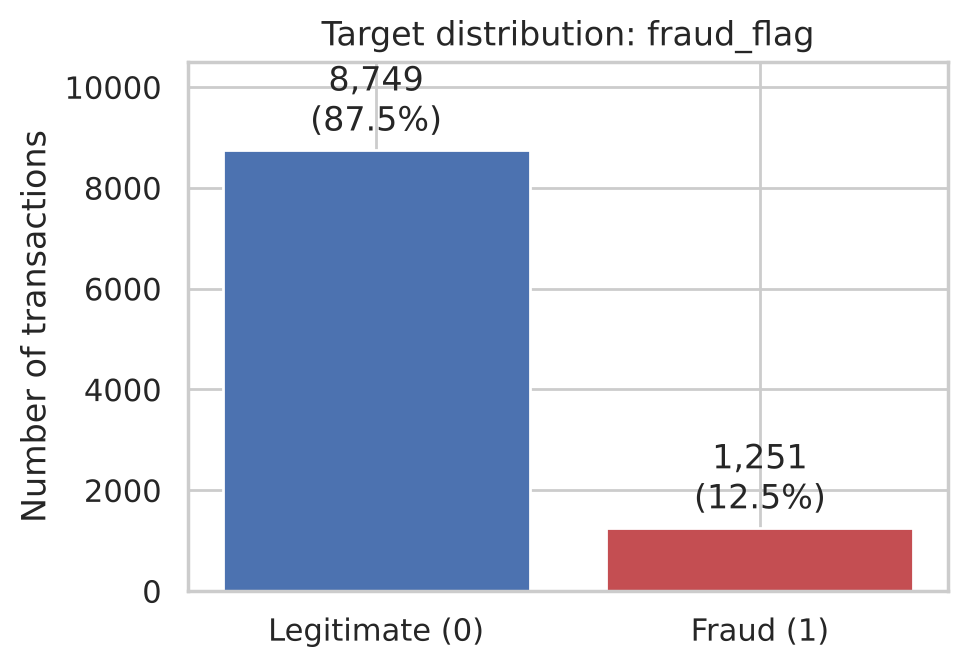

In [5]:
TARGET, ID_COL = "fraud_flag", "transaction_id"
CAT_COLS = ["payment_channel", "authentication_type"]
BIN_COLS = ["card_present_flag", "international_transaction_flag", "suspicious_ip_flag"]
NUM_COLS = [c for c in df.columns if c not in CAT_COLS + BIN_COLS + [TARGET, ID_COL]]

y = df[TARGET].astype(int)
X = df.drop(columns=[TARGET, ID_COL])           # identifier removed from the feature set

counts = y.value_counts().sort_index()
prevalence = y.mean()
print(f"Legitimate: {counts[0]:,} | Fraud: {counts[1]:,} | prevalence = {prevalence:.2%} | imbalance ratio = {counts[0]/counts[1]:.1f} : 1")

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Legitimate (0)", "Fraud (1)"], counts.values, color=[C_LEGIT, C_FRAUD])
ax.bar_label(bars, labels=[f"{v:,}\n({v/len(y):.1%})" for v in counts.values], padding=3)
ax.set_ylim(0, counts.max() * 1.2); ax.set_ylabel("Number of transactions")
ax.set_title("Target distribution: fraud_flag"); plt.tight_layout(); plt.show()

**Audit findings**

- **No missing values and no duplicates.** No rows need to be dropped or imputed today. We still place imputers inside the pipeline (median for numeric, mode for categorical/binary) as a defensive measure: a deployed model will eventually receive incomplete records, and the imputation statistics must then come from training data only.
- **Value ranges are plausible** (hours 0–23, scores 0–100, anomaly score 0–1). There are no impossible values to correct, and no extreme outliers; the numeric features are close to uniformly distributed, so no outlier clipping is applied.
- **Moderate class imbalance:** about 12.5% fraud (≈7 : 1). This is far less extreme than real card-fraud data (often below 0.5%), which matters for Part 2: with more than a thousand minority examples, augmentation is a hypothesis to test, not a given.
- `transaction_id` is a sequential counter and is removed from the features.

## 1.3 Validation strategy and leakage prevention

**Design.**

1. **Hold-out test set (20%, stratified)** — split off first and not used for any exploration, preprocessing fit, tuning, model selection or threshold choice. It is evaluated once, in Part 4.
2. **Development set (80%)** — all decisions are made here with **stratified 5-fold cross-validation**. Stratification keeps the fraud rate equal in every fold. For final comparisons we use **repeated** stratified CV (5 folds × 3 repeats) to measure the stability of the estimates rather than a single number.

Cross-validation is preferred to a single validation split because with ~1,000 development frauds a single 20% validation fold contains only ~200 positives, which makes one-off metric estimates noisy.

**Leakage risks and how each is prevented**

| Risk | Prevention in this notebook |
|---|---|
| Preprocessing statistics (medians, means/SDs, category lists) computed on data that later serves as validation/test | Every transformer lives inside a single `Pipeline`, which is re-fit on the training part of every CV fold and applied to the held-out part |
| Synthetic minority samples created from validation/test points, or leaking into them | Resampling is a step in an `imblearn` pipeline: it runs **only during `fit`** on the training fold and is skipped at prediction time. Validation and test data always keep the natural class distribution |
| Hyperparameters or threshold tuned on the test set | Tuning uses CV on the development set; the decision threshold is chosen from out-of-fold development predictions |
| Target-driven exploration on all rows | Feature–target analysis (Section 1.4) uses the development set only |
| Identifier leakage | `transaction_id` is dropped |
| Duplicated records across train and test | Verified: no duplicate rows or duplicate feature vectors |
| Temporal or entity leakage | The dataset has no timestamp and no customer/account ID, so a time-based or group-based split is not possible. A random stratified split is the only defensible option, and this limitation is discussed in Part 5 |
| **Target-proxy leakage** | `anomaly_score` looks like the output of an upstream detection system. Whether it is a legitimate feature depends on whether it is available at decision time; we investigate its influence explicitly (Sections 1.4 and 4.6) |

In [6]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

split_summary = pd.DataFrame({
    "rows": [len(X_dev), len(X_test)],
    "fraud": [y_dev.sum(), y_test.sum()],
    "fraud_rate": [y_dev.mean(), y_test.mean()],
}, index=["development (80%)", "test (20%)"])
display(split_summary)
assert set(X_dev.index).isdisjoint(X_test.index)

,rows,fraud,fraud_rate
development (80%),8000,1001,0.1251
test (20%),2000,250,0.1250


## 1.4 Exploratory signal analysis (development set only)

We measure how much each feature separates the classes on its own. For numeric and binary features we use the **univariate ROC-AUC** (0.5 = no separation), reported as `max(AUC, 1−AUC)` so that direction does not matter. For the two categorical features we show the fraud rate per category.

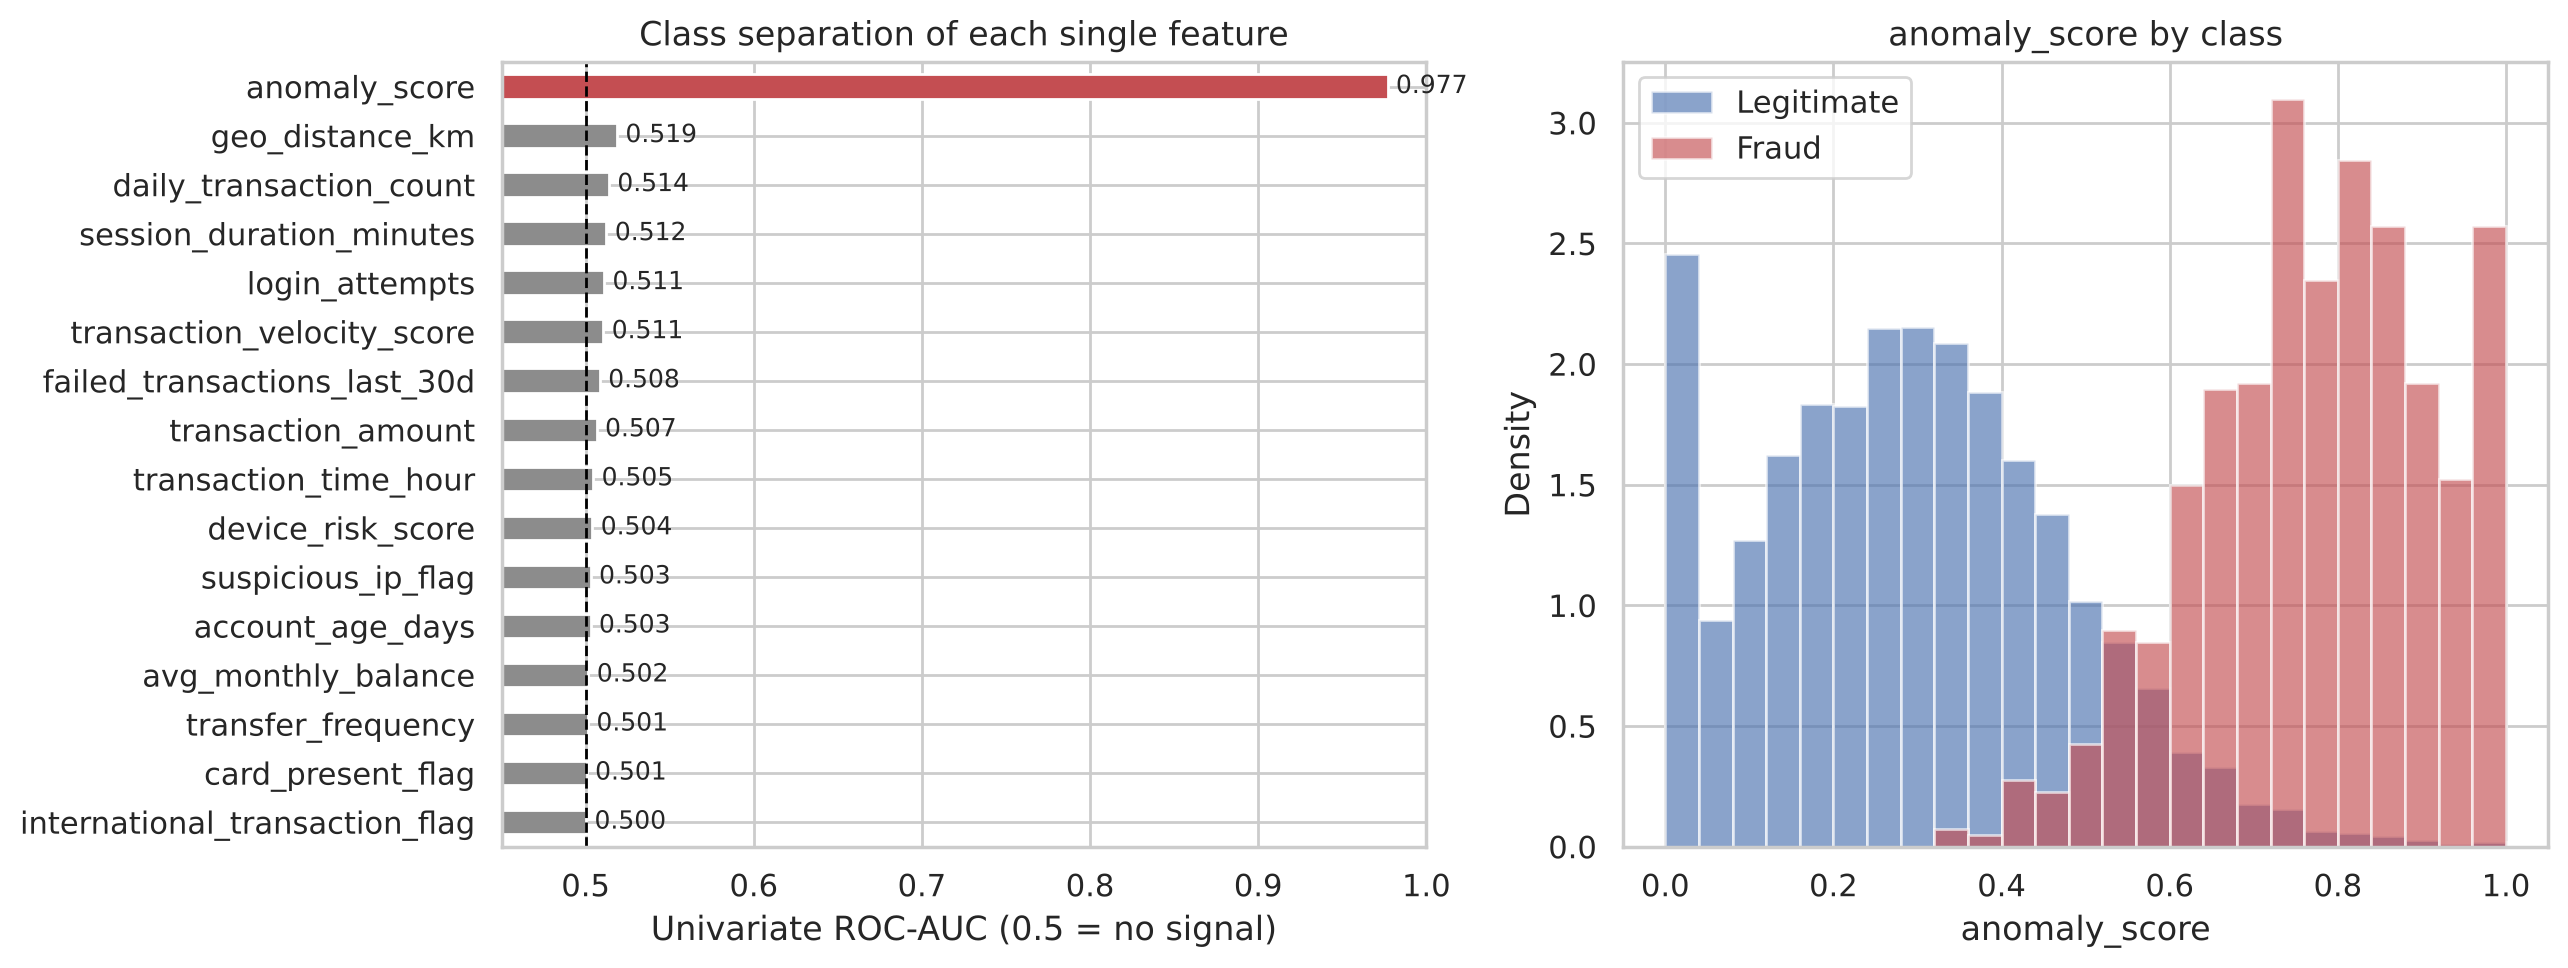

,fraud_rate,n
payment_channel,,
ATM,0.1405,619
Mobile App,0.1254,3843
POS Terminal,0.1074,931
Web Banking,0.1273,2607


,fraud_rate,n
authentication_type,,
Biometric,0.1214,1252
OTP,0.1296,3365
Password Only,0.1259,1469
Two-Factor Authentication,0.1191,1914


In [7]:
uni = {c: roc_auc_score(y_dev, X_dev[c]) for c in NUM_COLS + BIN_COLS}
uni = pd.Series(uni).apply(lambda a: max(a, 1 - a)).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
uni.plot.barh(ax=axes[0], color=[C_FRAUD if v > 0.6 else C_NEUTRAL for v in uni.values])
axes[0].axvline(0.5, color="black", ls="--", lw=1); axes[0].set_xlim(0.45, 1.0)
axes[0].set_xlabel("Univariate ROC-AUC (0.5 = no signal)"); axes[0].set_title("Class separation of each single feature")
for i, v in enumerate(uni.values): axes[0].text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)

bins = np.linspace(0, 1, 26)
axes[1].hist(X_dev.loc[y_dev == 0, "anomaly_score"], bins=bins, density=True, alpha=0.65, color=C_LEGIT, label="Legitimate")
axes[1].hist(X_dev.loc[y_dev == 1, "anomaly_score"], bins=bins, density=True, alpha=0.65, color=C_FRAUD, label="Fraud")
axes[1].set_xlabel("anomaly_score"); axes[1].set_ylabel("Density"); axes[1].legend()
axes[1].set_title("anomaly_score by class")
plt.tight_layout(); plt.show()

for c in CAT_COLS:
    display(pd.DataFrame({"fraud_rate": y_dev.groupby(X_dev[c]).mean(), "n": X_dev[c].value_counts()}).round(4))

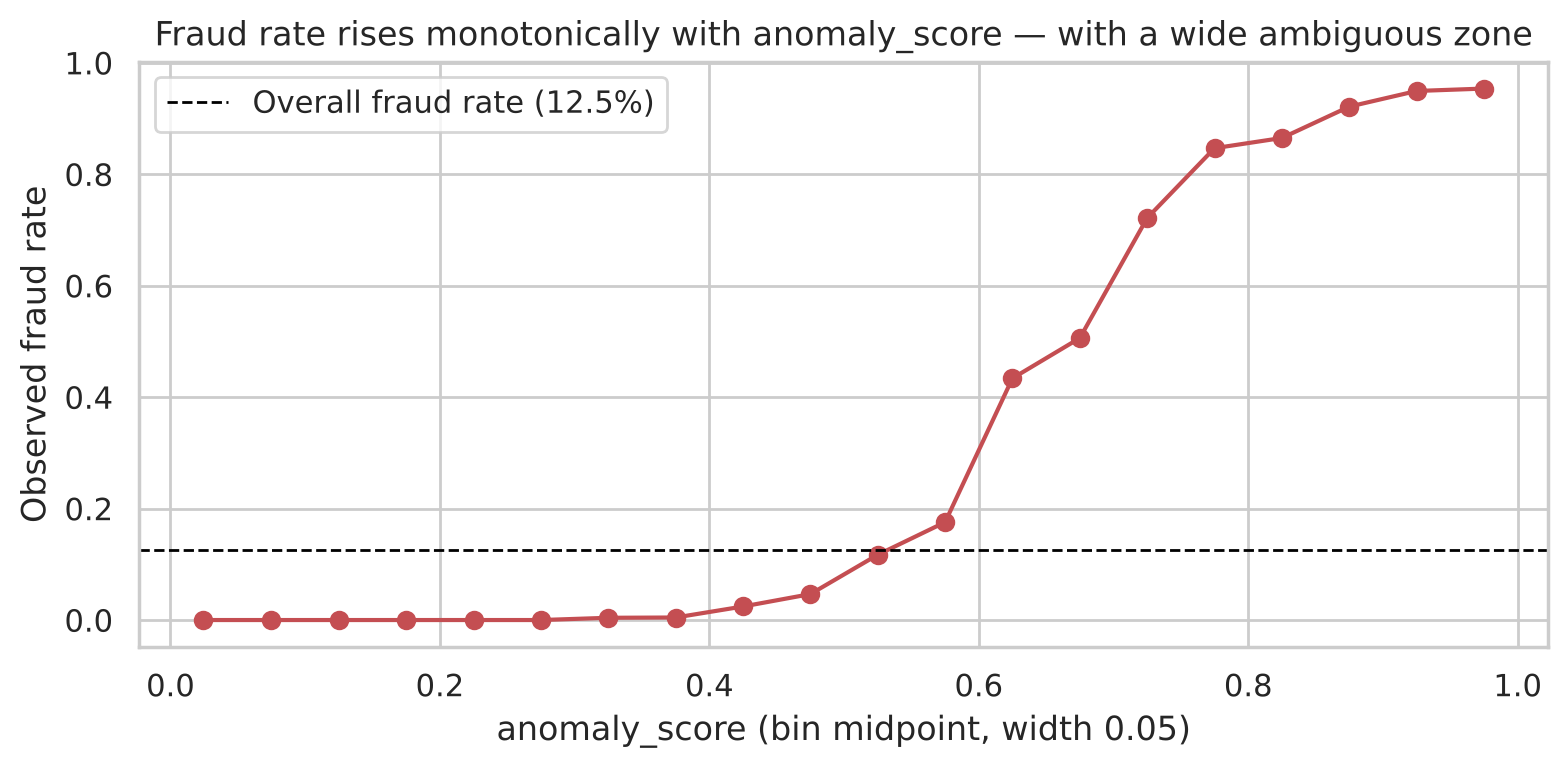

Largest absolute Spearman correlation between any two different features: 0.033


In [8]:
# Empirical fraud rate as a function of anomaly_score (development set)
tmp = pd.DataFrame({"anomaly_score": X_dev["anomaly_score"], "fraud": y_dev})
tmp["bin"] = pd.cut(tmp["anomaly_score"], np.linspace(0, 1, 21), include_lowest=True)
rate = tmp.groupby("bin", observed=True)["fraud"].agg(["mean", "size"])
mid = [iv.mid for iv in rate.index]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mid, rate["mean"], marker="o", color=C_FRAUD)
ax.set_xlabel("anomaly_score (bin midpoint, width 0.05)"); ax.set_ylabel("Observed fraud rate")
ax.set_title("Fraud rate rises monotonically with anomaly_score — with a wide ambiguous zone")
ax.axhline(y_dev.mean(), color="black", ls="--", lw=1, label=f"Overall fraud rate ({y_dev.mean():.1%})"); ax.legend()
plt.tight_layout(); plt.show()

corr = X_dev[NUM_COLS + BIN_COLS].corr(method="spearman")
off = corr.where(~np.eye(len(corr), dtype=bool)).abs().max().max()
print(f"Largest absolute Spearman correlation between any two different features: {off:.3f}")

**What the exploration shows (numbers from the saved run of this notebook)**

- **One feature carries essentially all of the signal.** `anomaly_score` alone separates the classes with a univariate ROC-AUC of about 0.98. Every other numeric or binary feature sits between 0.50 and 0.52, which is what random noise produces at this sample size. Fraud rates across payment channels (about 11–14%) and authentication types (about 12–13%) are also nearly flat.
- **The fraud rate is a smooth, monotone function of `anomaly_score`**: close to 0% below 0.4, rising steeply between 0.5 and 0.8, and above 90% at the top. Between roughly 0.5 and 0.75 the two classes overlap heavily. In that zone a transaction with a given score is sometimes fraud and sometimes not, and nothing else in the table (as far as univariate analysis can tell) explains which.
- **Features are mutually uncorrelated** (largest absolute Spearman correlation ≈ 0.03), so multicollinearity is not a concern for logistic regression, and there is no redundancy to remove.

**Implications for the design**

1. A model can only add value over a simple rule on `anomaly_score` if the other features interact with it, or with each other, in ways a univariate view cannot see. Tree ensembles are included in Part 3 specifically to test that.
2. The overlap zone sets a ceiling on achievable performance. We should expect all reasonable models to converge to a similar score, and should read small differences between models with caution.
3. `anomaly_score` must be treated as a potential **target proxy**. If it is produced by an upstream fraud engine *before* the decision is made, it is a legitimate (and excellent) input. If it is computed after investigation, or was itself trained on `fraud_flag`, using it is leakage. The dataset documentation does not say. We keep it, state the assumption explicitly ("available at scoring time"), and quantify what happens without it in Section 4.6.

## 1.5 Feature engineering

We add a small number of domain-motivated features. All of them are **row-wise, stateless transformations** (each value is computed from the same row only), so they cannot leak information between training and validation rows.

| Engineered feature | Definition | Rationale |
|---|---|---|
| `log_amount_to_balance` | `log1p(transaction_amount / (avg_monthly_balance + 1))` | A large payment relative to the customer's normal balance is more suspicious than a large payment in absolute terms; the log tames the heavy right tail of the ratio |
| `failed_per_login` | `failed_transactions_last_30d / login_attempts` | Intensity of failures relative to activity |
| `hour_sin`, `hour_cos` | Cyclical encoding of `transaction_time_hour` | 23:00 and 00:00 are adjacent in reality but far apart numerically; matters for linear models |
| `is_night` | 1 if hour < 6 | Classic fraud heuristic: unusual-hour activity |
| `risk_interaction` | `device_risk_score × transaction_velocity_score / 100` | Lets a linear model express "risky device **and** rapid activity" |

Whether these features actually help is an empirical question, tested in Section 1.7 rather than assumed.

In [9]:
FE_NUM = ["log_amount_to_balance", "failed_per_login", "hour_sin", "hour_cos", "risk_interaction"]
FE_BIN = ["is_night"]

def add_features(data: pd.DataFrame) -> pd.DataFrame:
    """Stateless, row-wise feature engineering (safe to apply before or after splitting)."""
    out = data.copy()
    out["log_amount_to_balance"] = np.log1p(out["transaction_amount"] / (out["avg_monthly_balance"] + 1.0))
    out["failed_per_login"] = out["failed_transactions_last_30d"] / out["login_attempts"].clip(lower=1)
    angle = 2 * np.pi * out["transaction_time_hour"] / 24.0
    out["hour_sin"], out["hour_cos"] = np.sin(angle), np.cos(angle)
    out["is_night"] = (out["transaction_time_hour"] < 6).astype(int)
    out["risk_interaction"] = out["device_risk_score"] * out["transaction_velocity_score"] / 100.0
    return out

add_features(X_dev.head(3))[FE_NUM + FE_BIN]

,log_amount_to_balance,failed_per_login,hour_sin,hour_cos,risk_interaction,is_night
5940,0.0436,0.4000,-0.5000,-0.8660,12.3892,0
5416,0.0127,7.0000,-0.7071,0.7071,15.7126,0
3962,0.0284,0.3000,-0.8660,-0.5000,85.0850,0


## 1.6 The preprocessing pipeline

One function builds every pipeline used in this notebook, so all models are compared under identical preprocessing:

```
raw features
  └─ 1. features    FunctionTransformer(add_features)            (optional, stateless)
  └─ 2. preprocess  ColumnTransformer
        ├─ numeric      median imputation → StandardScaler
        ├─ binary       most-frequent imputation
        └─ categorical  most-frequent imputation → OrdinalEncoder (integer codes)
  └─ 3. sampler     none | RandomOverSampler | SMOTENC | RandomUnderSampler   (training folds only)
  └─ 4. onehot      OneHotEncoder on the categorical codes
  └─ 5. model
```

**Justification of each choice**

- **Median / most-frequent imputation.** There are no missing values today, so the imputers are inactive; they exist so the fitted pipeline is deployable on incomplete records. The median is robust to skew. Because they sit inside the pipeline, their statistics are learned from training folds only.
- **Standard scaling.** Features live on very different scales (`avg_monthly_balance` up to 500,000 vs. `anomaly_score` in [0, 1]). Scaling is required for regularised logistic regression (the penalty is scale-dependent and the solver converges faster) and for SMOTE's nearest-neighbour distances (otherwise the balance column alone would decide who the "neighbours" are). Tree models are invariant to monotone scaling, so it is harmless for them and keeps the comparison uniform.
- **One-hot encoding** for the two nominal variables (4 levels each) — no artificial ordering is imposed; `handle_unknown="ignore"` prevents failures on unseen categories in production.
- **Why the ordinal → sampler → one-hot order?** SMOTE interpolates between neighbours. Interpolating one-hot columns would create impossible records (e.g. 0.4 "ATM" + 0.6 "Web Banking"). **SMOTENC** handles categorical columns by majority vote among neighbours, but needs each categorical variable as a single column, so the one-hot expansion happens after resampling.

In [10]:
def make_sampler(name, cat_idx):
    if name in (None, "none"):
        return "passthrough"
    if name == "ros":
        return RandomOverSampler(random_state=RANDOM_STATE)
    if name == "smotenc":
        return SMOTENC(categorical_features=cat_idx, k_neighbors=5, random_state=RANDOM_STATE)
    if name == "rus":
        return RandomUnderSampler(random_state=RANDOM_STATE)
    raise ValueError(name)

def make_pipeline(model, sampler="none", use_fe=False, drop=()):
    """Full leakage-safe pipeline: feature engineering -> preprocessing -> (resampling) -> one-hot -> model."""
    num = [c for c in NUM_COLS + (FE_NUM if use_fe else []) if c not in drop]
    bin_ = [c for c in BIN_COLS + (FE_BIN if use_fe else []) if c not in drop]
    cat = [c for c in CAT_COLS if c not in drop]

    preprocess = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("bin", SimpleImputer(strategy="most_frequent"), bin_),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), cat),
    ], remainder="drop")

    n_num, n_bin = len(num), len(bin_)
    nominal_idx = list(range(n_num + n_bin, n_num + n_bin + len(cat)))      # columns to one-hot encode
    discrete_idx = list(range(n_num, n_num + n_bin + len(cat)))            # columns SMOTENC must not interpolate

    onehot = ColumnTransformer([("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_idx)],
                               remainder="passthrough")
    return ImbPipeline([
        ("features", FunctionTransformer(add_features) if use_fe else "passthrough"),
        ("preprocess", preprocess),
        ("sampler", make_sampler(sampler, discrete_idx)),
        ("onehot", onehot),
        ("model", model),
    ])

SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "recall": "recall",
           "precision": "precision", "f1": "f1", "brier": "neg_brier_score"}

def cv_table(pipelines: dict, X_, y_, cv=cv5, train_scores=False):
    """Cross-validate several pipelines on identical folds; return per-fold results and a mean ± sd summary."""
    folds = {}
    for name, pipe in pipelines.items():
        res = cross_validate(pipe, X_, y_, cv=cv, scoring=SCORING, n_jobs=-1, return_train_score=train_scores)
        folds[name] = pd.DataFrame({k.replace("test_", ""): v for k, v in res.items() if k.startswith(("test_", "train_"))})
        folds[name]["brier"] = -folds[name]["brier"]
        if train_scores: folds[name]["train_brier"] = -folds[name]["train_brier"]
    summary = pd.DataFrame({n: f.mean() for n, f in folds.items()}).T
    summary.insert(1, "pr_auc_sd", [folds[n]["pr_auc"].std() for n in folds])
    return folds, summary

make_pipeline(LogisticRegression(max_iter=2000), sampler="smotenc", use_fe=True)

,steps,"[('features', ...), ('preprocess', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...x7f8cbf7c63e0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary of additional keyword arguments to pass to func... versionadded:: 0.18",None


## 1.7 Baselines and the value of feature engineering

Before any tuning we establish reference points on the development set (5-fold CV, identical folds):

- **No-skill baseline** — predicts the prevalence for everyone. Its PR-AUC equals the fraud rate.
- **Raw `anomaly_score` ranking** — no model at all: rank transactions by the upstream anomaly score. Any model we build must beat this to justify its existence.
- **Logistic regression and gradient boosting, default settings**, with and without the engineered features.

In [11]:
def raw_score_cv(col, X_, y_, cv):
    rows = []
    for _, va in cv.split(X_, y_):
        s, t = X_[col].iloc[va], y_.iloc[va]
        rows.append({"pr_auc": average_precision_score(t, s), "roc_auc": roc_auc_score(t, s)})
    return pd.DataFrame(rows)

base_lr = LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
base_xgb = XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, subsample=0.8,
                         eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1)

baselines = {
    "No-skill (prevalence)": make_pipeline(DummyClassifier(strategy="prior")),
    "LogReg | raw features": make_pipeline(clone(base_lr), use_fe=False),
    "LogReg | + engineered": make_pipeline(clone(base_lr), use_fe=True),
    "XGBoost | raw features": make_pipeline(clone(base_xgb), use_fe=False),
    "XGBoost | + engineered": make_pipeline(clone(base_xgb), use_fe=True),
}
base_folds, base_summary = cv_table(baselines, X_dev, y_dev)
raw = raw_score_cv("anomaly_score", X_dev, y_dev, cv5)
base_summary.loc["Raw anomaly_score ranking (no model)", ["pr_auc", "pr_auc_sd", "roc_auc"]] = [raw.pr_auc.mean(), raw.pr_auc.std(), raw.roc_auc.mean()]
display(base_summary[["pr_auc", "pr_auc_sd", "roc_auc", "recall", "precision", "f1", "brier"]])

for m in ["LogReg", "XGBoost"]:
    d = base_folds[f"{m} | + engineered"]["pr_auc"] - base_folds[f"{m} | raw features"]["pr_auc"]
    t, p = stats.ttest_rel(base_folds[f"{m} | + engineered"]["pr_auc"], base_folds[f"{m} | raw features"]["pr_auc"])
    print(f"{m}: PR-AUC change from engineered features = {d.mean():+.4f} (per-fold: {np.round(d.values, 4)}), paired t-test p = {p:.2f}")

,pr_auc,pr_auc_sd,roc_auc,recall,precision,f1,brier
No-skill (prevalence),0.1251,0.0003,0.5000,0.0000,0.0000,0.0000,0.1095
LogReg | raw features,0.8567,0.0210,0.9765,0.7412,0.8225,0.7794,0.0384
LogReg | + engineered,0.8544,0.0221,0.9764,0.7442,0.8189,0.7792,0.0385
XGBoost | raw features,0.8456,0.0228,0.9751,0.7792,0.8004,0.7892,0.0391
XGBoost | + engineered,0.8433,0.0258,0.9749,0.7712,0.7993,0.7846,0.0392
Raw anomaly_score ranking (no model),0.8533,0.0225,0.9770,NaN,NaN,NaN,NaN


LogReg: PR-AUC change from engineered features = -0.0023 (per-fold: [-0.0037  0.0013 -0.0014 -0.0049 -0.0026]), paired t-test p = 0.10
XGBoost: PR-AUC change from engineered features = -0.0023 (per-fold: [-0.0024  0.0087 -0.004  -0.0126 -0.0013]), paired t-test p = 0.53


**Interpretation**

- **The no-skill PR-AUC is 0.125** (the prevalence); this is the floor against which everything is read.
- **Ranking by raw `anomaly_score` already reaches PR-AUC ≈ 0.853 and ROC-AUC ≈ 0.977 with no model at all.** Default logistic regression (0.857) and default XGBoost (0.846) land in the same place. This confirms implication 2 above.
- **The engineered features do not help.** PR-AUC changes by about −0.002 for both models, the per-fold differences change sign, and the paired tests are not significant. This is consistent with the univariate analysis: ratios, cyclical encodings and interactions of uninformative features are still uninformative.
- **Decision:** following parsimony, the engineered features are **not** used in the remaining experiments (`use_fe=False`). They add dimensions (which hurts distance-based resampling and increases variance) without adding signal. The code is kept so the test is reproducible.
- **At the default 0.5 threshold, recall is only about 0.74** for logistic regression even though ranking is excellent. This is the symptom of imbalance investigated in Part 2.

---
# Part 2 — Data Generation / Augmentation

## 2.1 Is augmentation necessary? Diagnosis

Three questions decide whether augmentation is warranted:

1. **How severe is the imbalance?** 12.5% fraud (7 : 1) — *moderate*, and far from the 100 : 1 to 1000 : 1 ratios typical of real card-fraud data.
2. **Are minority samples sparse in absolute terms?** No — the development set has about 1,000 frauds, 800 in every training fold. SMOTE-type methods help most when the minority class is too small to outline its own region of feature space.
3. **Does the imbalance actually hurt the model?** The baseline table above gives the answer: ranking quality (PR-AUC, ROC-AUC) is already high, but **recall at the default 0.5 threshold is low**. That pattern indicates the classifier ranks transactions well but its probabilities are (correctly) anchored to a 12.5% prior, so few cases pass 0.5. This is a *decision-threshold* problem as much as a *data* problem.

**Conclusion of the diagnosis:** augmentation is not obviously necessary, but imbalance does depress default-threshold recall, so we test it properly. The hypothesis is: *"rebalancing the training data improves the model's ability to rank and detect fraud on unseen, naturally distributed data."* A fair test must separate a real improvement in ranking from a mere shift of the decision threshold.

## 2.2 Methods compared

| Strategy | Type | How it works | Main risk |
|---|---|---|---|
| None | — | Train on the natural distribution | Low recall at 0.5 |
| Class weighting | Cost-sensitive (no new data) | Errors on fraud weigh ≈7× more in the loss | Inflated probabilities |
| Random oversampling (ROS) | Duplication | Repeats minority rows until classes are balanced | Overfitting to repeated points |
| **SMOTENC** | **Synthetic generation** | Creates new minority rows by interpolating between a fraud and one of its 5 nearest fraud neighbours; categorical/binary columns take the neighbours' majority value | Synthetic points in overlap regions, distribution distortion |
| Random undersampling (RUS) | Deletion | Discards majority rows | Throws away 6/7 of legitimate data |

**Why SMOTENC rather than plain SMOTE or ADASYN?** The data mixes continuous with categorical and binary features. Plain SMOTE and ADASYN interpolate every column, which would produce invalid values such as `card_present_flag = 0.37`. SMOTENC is the SMOTE variant designed for mixed data. A generative model (CTGAN/TVAE) was considered but is not justified here: with ~800 minority rows per fold such models are hard to train reliably and add a second source of variance.

**Protocol.** Each strategy is a pipeline step, so resampling is applied **strictly to the training folds**; validation folds keep the real 12.5% prevalence. Two different learners (logistic regression and random forest) are used so the conclusion does not depend on one model family. All strategies see identical folds.

In [12]:
rf_base = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=1)
STRATEGIES = ["none", "class_weight", "ros", "smotenc", "rus"]
LABELS = {"none": "None (natural)", "class_weight": "Class weighting", "ros": "Random oversampling",
          "smotenc": "SMOTENC (synthetic)", "rus": "Random undersampling"}

def strategy_pipeline(model, strategy):
    model = clone(model)
    if strategy == "class_weight":
        model.set_params(class_weight="balanced")
        return make_pipeline(model, sampler="none")
    return make_pipeline(model, sampler=strategy)

aug_pipes = {(m_name, LABELS[s]): strategy_pipeline(m, s)
             for m_name, m in [("LogReg", base_lr), ("RandomForest", rf_base)] for s in STRATEGIES}
aug_folds, aug_summary = cv_table(aug_pipes, X_dev, y_dev)
aug_summary.index = pd.MultiIndex.from_tuples(aug_summary.index, names=["model", "strategy"])
display(aug_summary[["pr_auc", "pr_auc_sd", "roc_auc", "recall", "precision", "f1", "brier"]])

pr_auc  pr_auc_sd  roc_auc  recall  \
model        strategy                                                   
LogReg       None (natural)        0.8567     0.0210   0.9765  0.7412   
             Class weighting       0.8558     0.0194   0.9763  0.9271   
             Random oversampling   0.8560     0.0200   0.9764  0.9301   
             SMOTENC (synthetic)   0.8497     0.0198   0.9751  0.9031   
             Random undersampling  0.8518     0.0210   0.9755  0.9301   
RandomForest None (natural)        0.8295     0.0177   0.9662  0.7702   
             Class weighting       0.8052     0.0388   0.9709  0.9091   
             Random oversampling   0.8203     0.0285   0.9699  0.8841   
             SMOTENC (synthetic)   0.7787     0.0161   0.9662  0.8901   
             Random undersampling  0.7890     0.0291   0.9689  0.9440   

                                   precision     f1  brier  
model        strategy                                       
LogReg       None (natural)           0.8225 0.7794 0.0384  
             Class weighting          0.6237 0.7456 0.0596  
             Random oversampling      0.6250 0.7474 0.0596  
             SMOTENC (synthetic)      0.6561 0.7598 0.0535  
             Random undersampling     0.6014 0.7303 0.0634  
RandomForest None (natural)           0.8106 0.7891 0.0408  
             Class weighting          0.6430 0.7527 0.0529  
             Random oversampling      0.6959 0.7782 0.0461  
             SMOTENC (synthetic)      0.6901 0.7770 0.0484  
             Random undersampling     0.5815 0.7193 0.0725

In [13]:
# Verify that resampling happens on the training fold only (one fold shown)
tr, va = next(cv5.split(X_dev, y_dev))
demo_pipe = make_pipeline(clone(base_lr), sampler="smotenc")
Xt = demo_pipe.named_steps["preprocess"].fit_transform(X_dev.iloc[tr])
Xr, yr = demo_pipe.named_steps["sampler"].fit_resample(Xt, y_dev.iloc[tr])
print(f"Training fold before SMOTENC : {len(tr):,} rows, fraud rate {y_dev.iloc[tr].mean():.1%}")
print(f"Training fold after  SMOTENC : {len(yr):,} rows, fraud rate {yr.mean():.1%}  ({len(yr) - len(tr):,} synthetic frauds)")
print(f"Validation fold (untouched)  : {len(va):,} rows, fraud rate {y_dev.iloc[va].mean():.1%}")

Training fold before SMOTENC : 6,400 rows, fraud rate 12.5%
Training fold after  SMOTENC : 11,198 rows, fraud rate 50.0%  (4,798 synthetic frauds)
Validation fold (untouched)  : 1,600 rows, fraud rate 12.5%


In [14]:
# Paired comparison against "None" on identical folds: does the strategy change RANKING quality?
rows = []
for m in ["LogReg", "RandomForest"]:
    ref = aug_folds[(m, LABELS["none"])]
    for s in STRATEGIES[1:]:
        cur = aug_folds[(m, LABELS[s])]
        d = cur["pr_auc"] - ref["pr_auc"]
        rows.append({"model": m, "strategy": LABELS[s], "ΔPR-AUC (mean)": d.mean(), "folds improved": f"{(d > 0).sum()}/5",
                     "paired t-test p": stats.ttest_rel(cur["pr_auc"], ref["pr_auc"]).pvalue,
                     "Δrecall@0.5": (cur["recall"] - ref["recall"]).mean(),
                     "Δprecision@0.5": (cur["precision"] - ref["precision"]).mean(),
                     "ΔBrier (higher = worse)": (cur["brier"] - ref["brier"]).mean()})
display(pd.DataFrame(rows).set_index(["model", "strategy"]))

ΔPR-AUC (mean) folds improved  \
model        strategy                                              
LogReg       Class weighting              -0.0009            1/5   
             Random oversampling          -0.0007            2/5   
             SMOTENC (synthetic)          -0.0070            0/5   
             Random undersampling         -0.0049            1/5   
RandomForest Class weighting              -0.0243            2/5   
             Random oversampling          -0.0092            1/5   
             SMOTENC (synthetic)          -0.0508            0/5   
             Random undersampling         -0.0405            0/5   

                                   paired t-test p  Δrecall@0.5  \
model        strategy                                             
LogReg       Class weighting                0.4393       0.1858   
             Random oversampling            0.2872       0.1888   
             SMOTENC (synthetic)            0.0191       0.1619   
             Random undersampling           0.1523       0.1888   
RandomForest Class weighting                0.1114       0.1389   
             Random oversampling            0.1613       0.1139   
             SMOTENC (synthetic)            0.0001       0.1199   
             Random undersampling           0.0319       0.1739   

                                   Δprecision@0.5  ΔBrier (higher = worse)  
model        strategy                                                       
LogReg       Class weighting              -0.1988                   0.0212  
             Random oversampling          -0.1975                   0.0212  
             SMOTENC (synthetic)          -0.1664                   0.0151  
             Random undersampling         -0.2212                   0.0250  
RandomForest Class weighting              -0.1676                   0.0121  
             Random oversampling          -0.1147                   0.0053  
             SMOTENC (synthetic)          -0.1205                   0.0076  
             Random undersampling         -0.2291                   0.0317

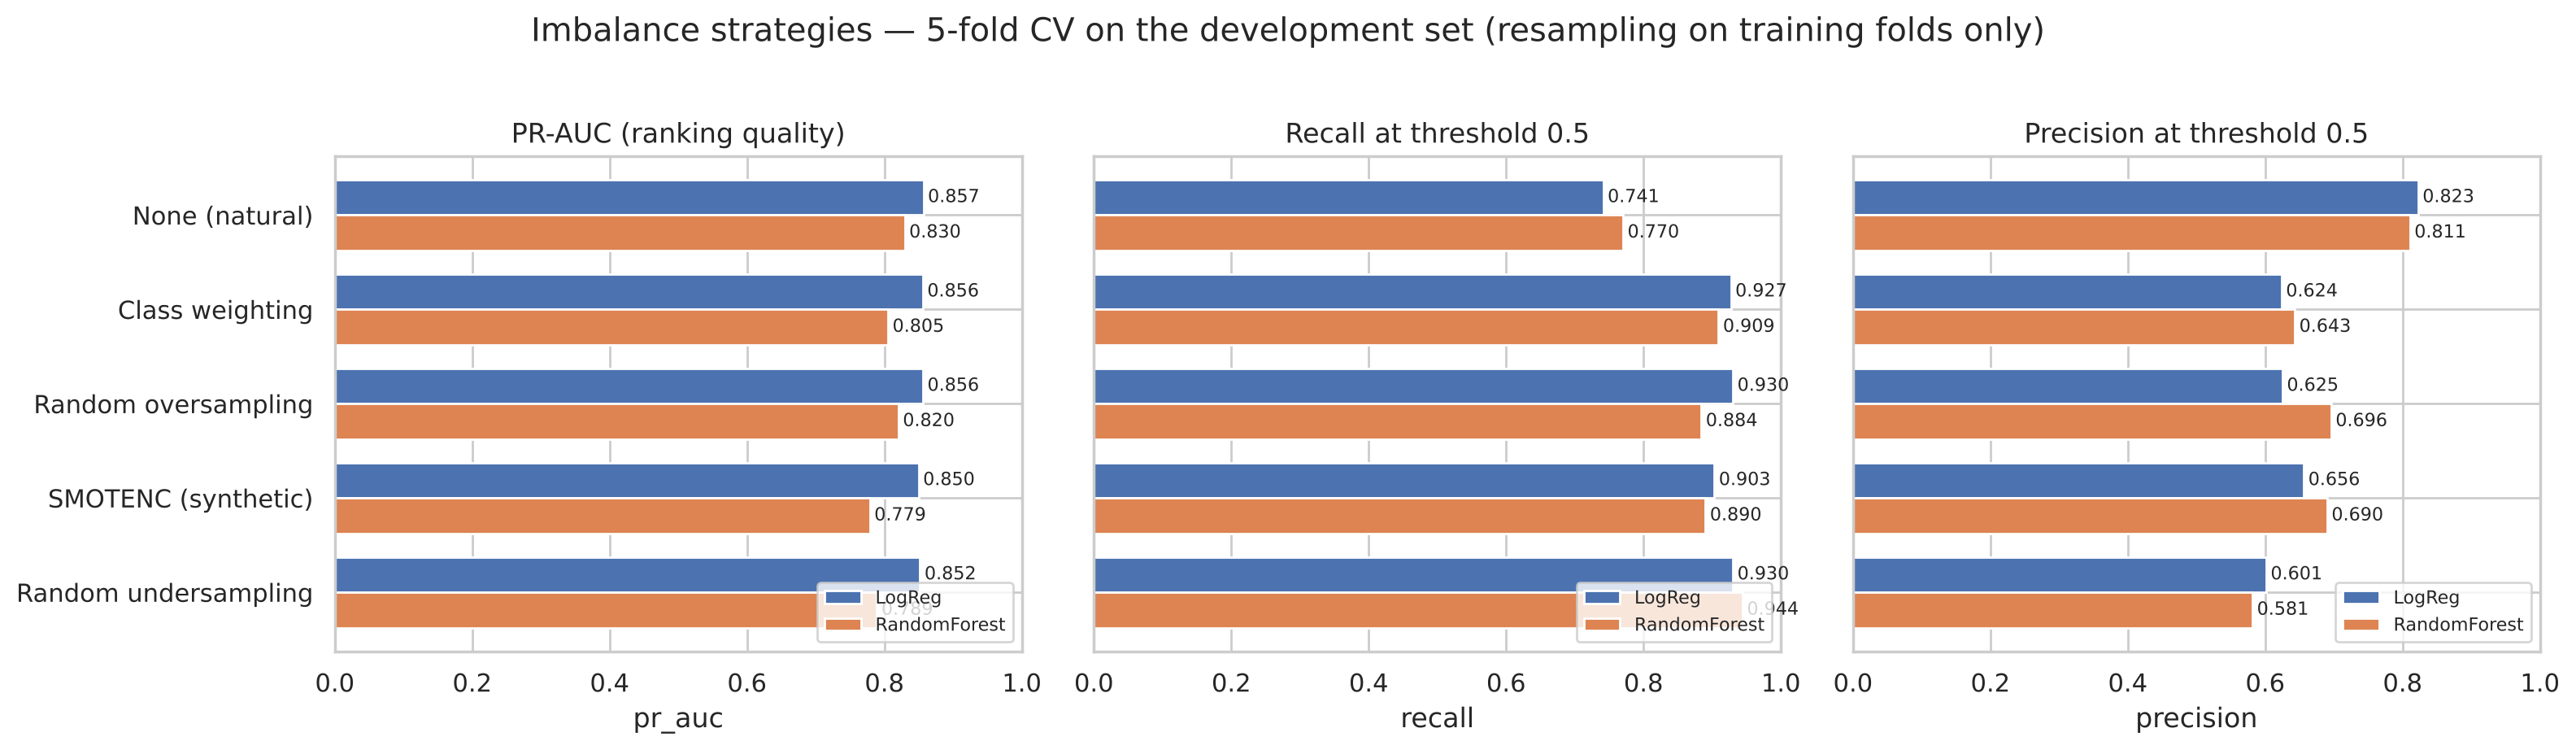

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
order = [LABELS[s] for s in STRATEGIES]
for ax, metric, title in zip(axes, ["pr_auc", "recall", "precision"],
                             ["PR-AUC (ranking quality)", "Recall at threshold 0.5", "Precision at threshold 0.5"]):
    plot_df = aug_summary[metric].unstack("model").loc[order]
    plot_df.plot.barh(ax=ax, color=[C_LEGIT, "#DD8452"], width=0.75)
    ax.set_title(title); ax.set_xlim(0, 1); ax.set_xlabel(metric); ax.set_ylabel(""); ax.invert_yaxis()
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8, padding=2)
    ax.legend(title="", loc="lower right", fontsize=8)
plt.suptitle("Imbalance strategies — 5-fold CV on the development set (resampling on training folds only)", y=1.02)
plt.tight_layout(); plt.show()

## 2.3 Is the recall gain real? Threshold-matched comparison

Rebalancing raises recall at 0.5, but it also lowers precision. To check whether augmentation gives a *better* classifier or simply a *different operating point*, we take out-of-fold predictions from the model trained **without** augmentation and from the model trained **with SMOTENC**, and compare them over the whole precision–recall curve, and at matched recall.

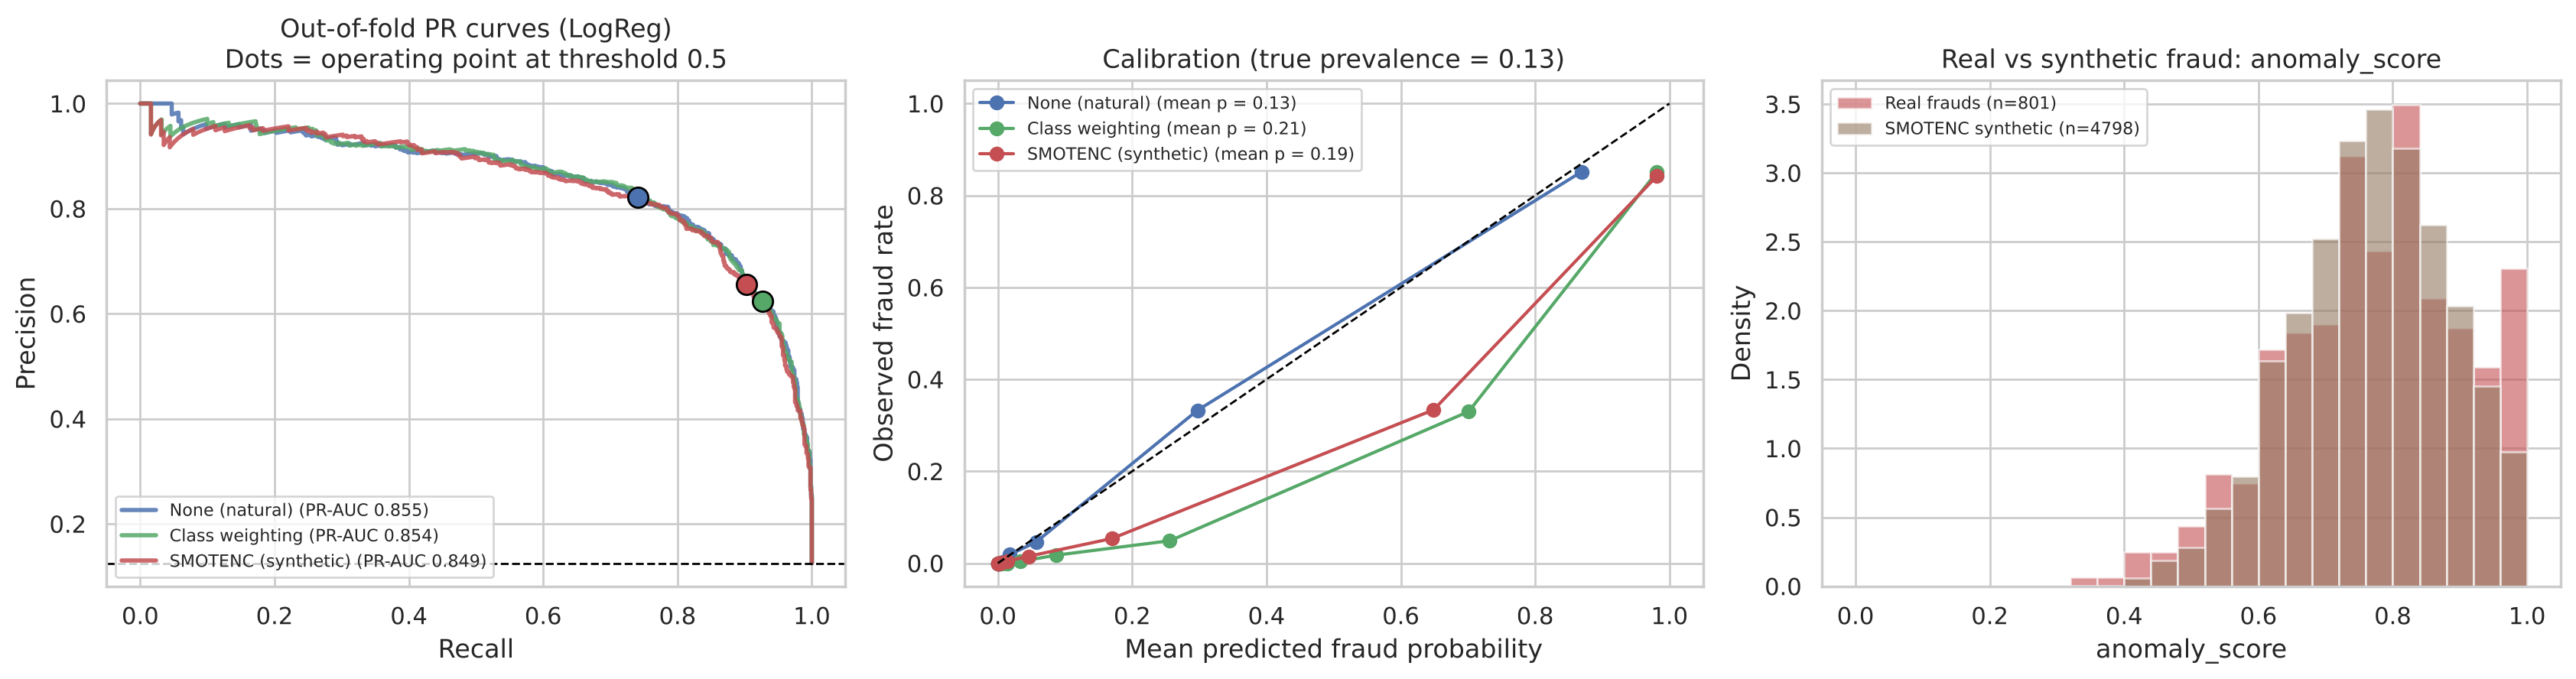

Precision achieved at the SAME recall (out-of-fold, LogReg):


,None (natural),Class weighting,SMOTENC (synthetic)
target recall,,,
0.7000,0.8458,0.8507,0.8298
0.8000,0.7899,0.7817,0.7876
0.9000,0.6625,0.6724,0.6615


Real vs synthetic minority — two-sample KS test per numeric feature (largest 5):


,KS statistic,p-value
login_attempts,0.0785,0.0004
transaction_time_hour,0.0637,0.0072
anomaly_score,0.0625,0.0089
geo_distance_km,0.0565,0.0240
failed_transactions_last_30d,0.0542,0.0339


Std. dev. ratio synthetic/real, averaged over numeric features: 0.915


In [16]:
oof = {}
for s in ["none", "class_weight", "smotenc"]:
    oof[s] = cross_val_predict(strategy_pipeline(base_lr, s), X_dev, y_dev, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]

def precision_at_recall(y_true, score, target):
    p, r, _ = precision_recall_curve(y_true, score)
    return p[r >= target].max()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
colors = {"none": C_LEGIT, "class_weight": "#55A868", "smotenc": C_FRAUD}
for s in oof:
    p, r, _ = precision_recall_curve(y_dev, oof[s])
    axes[0].plot(r, p, color=colors[s], lw=2, alpha=0.85, label=f"{LABELS[s]} (PR-AUC {average_precision_score(y_dev, oof[s]):.3f})")
    pred = oof[s] >= 0.5
    axes[0].scatter(recall_score(y_dev, pred), precision_score(y_dev, pred), color=colors[s], s=90, edgecolor="black", zorder=5)
axes[0].axhline(y_dev.mean(), color="black", ls="--", lw=1)
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].legend(fontsize=8, loc="lower left")
axes[0].set_title("Out-of-fold PR curves (LogReg)\nDots = operating point at threshold 0.5")

for s in oof:
    frac_pos, mean_pred = calibration_curve(y_dev, oof[s], n_bins=10, strategy="quantile")
    axes[1].plot(mean_pred, frac_pos, marker="o", color=colors[s], label=f"{LABELS[s]} (mean p = {oof[s].mean():.2f})")
axes[1].plot([0, 1], [0, 1], color="black", ls="--", lw=1)
axes[1].set_xlabel("Mean predicted fraud probability"); axes[1].set_ylabel("Observed fraud rate")
axes[1].set_title(f"Calibration (true prevalence = {y_dev.mean():.2f})"); axes[1].legend(fontsize=8)

# Distribution of real vs synthetic minority points on the dominant feature
num_names = NUM_COLS
syn = pd.DataFrame(Xr[len(tr):, :len(num_names)], columns=num_names)
real = pd.DataFrame(Xt[y_dev.iloc[tr].values == 1, :len(num_names)], columns=num_names)
sc = demo_pipe.named_steps["preprocess"].named_transformers_["num"].named_steps["scale"]
j = num_names.index("anomaly_score")
real_a, syn_a = real["anomaly_score"] * sc.scale_[j] + sc.mean_[j], syn["anomaly_score"] * sc.scale_[j] + sc.mean_[j]
axes[2].hist(real_a, bins=bins, density=True, alpha=0.6, color=C_FRAUD, label=f"Real frauds (n={len(real_a)})")
axes[2].hist(syn_a, bins=bins, density=True, alpha=0.6, color="#937860", label=f"SMOTENC synthetic (n={len(syn_a)})")
axes[2].set_xlabel("anomaly_score"); axes[2].set_ylabel("Density"); axes[2].legend(fontsize=8)
axes[2].set_title("Real vs synthetic fraud: anomaly_score")
plt.tight_layout(); plt.show()

rows = []
for target in [0.70, 0.80, 0.90]:
    rows.append({"target recall": target, **{LABELS[s]: precision_at_recall(y_dev, oof[s], target) for s in oof}})
print("Precision achieved at the SAME recall (out-of-fold, LogReg):")
display(pd.DataFrame(rows).set_index("target recall"))

ks = pd.DataFrame({c: stats.ks_2samp(real[c], syn[c]) for c in num_names}, index=["KS statistic", "p-value"]).T
print("Real vs synthetic minority — two-sample KS test per numeric feature (largest 5):")
display(ks.sort_values("KS statistic", ascending=False).head(5))
print(f"Std. dev. ratio synthetic/real, averaged over numeric features: {(syn.std() / real.std()).mean():.3f}")

## 2.4 Findings: was augmentation beneficial?

**Before / after comparison (5-fold CV, development set)**

| Question | Evidence | Answer |
|---|---|---|
| Does rebalancing improve **ranking** (PR-AUC)? | Logistic regression: −0.001 (class weights), −0.001 (ROS), **−0.007 (SMOTENC, worse in 5/5 folds)**, −0.005 (RUS). Random forest: −0.024, −0.009, **−0.051 (SMOTENC, worse in 5/5 folds)**, −0.040 | **No.** No strategy improves PR-AUC for either learner; synthetic generation is the most harmful one |
| Does it improve **recall at 0.5**? | Recall rises from ≈0.74–0.77 to ≈0.88–0.94 | Yes, but… |
| …at what price? | Precision falls from ≈0.82 to ≈0.60–0.70; F1 falls for every strategy | The gain is paid for entirely in false alarms |
| Is this a better classifier or a moved threshold? | At **matched recall** (0.70 / 0.80 / 0.90), precision of the natural, weighted and SMOTENC models differs by less than 0.02 and the PR curves lie on top of each other | **A moved threshold.** The same operating points are available from the un-augmented model by lowering its threshold |
| Side effects on probabilities? | Brier score worsens from ≈0.038 to 0.054–0.063; mean predicted fraud probability rises from 0.13 (the true prevalence) to 0.19–0.21 | Rebalanced models systematically over-state fraud risk |

**Why SMOTENC does not help here (and hurts the forest).** SMOTE helps when the minority class is too sparse for the learner to delineate its region. Here the minority class has ~800 examples per training fold and its region is simple: high `anomaly_score`. The errors come from the *overlap* zone, where fraud and legitimate transactions are intrinsically mixed; creating more fraud-labelled points inside that zone does not make it more separable. In addition, nearest neighbours are computed in a space where one dimension is informative and about seventeen are noise, so the "neighbours" are close to random frauds and interpolation fills the noise dimensions with artificial structure. A flexible learner such as a random forest then spends capacity fitting that artificial density, which is exactly the loss in PR-AUC we observe.

**Risks of augmentation, as observed in this dataset**

- **Overfitting to synthetic data.** The forest's PR-AUC drop under SMOTENC and ROS is direct evidence: the model learns patterns of the resampled set that do not exist in real validation data.
- **Distribution distortion.** Synthetic frauds are not distributed like real ones. Interpolation contracts the minority cloud (average standard-deviation ratio synthetic/real ≈ 0.92) and under-represents the extremes: real frauds have a pronounced spike at `anomaly_score` ≈ 0.95–1.0 and a tail below 0.5 which the synthetic sample reproduces only weakly. KS tests detect differences on several features, although the effect sizes are small (KS ≤ 0.08). Resampling also changes the class prior from 12.5% to 50%, which is why calibrated probabilities are lost.
- **Bias amplification.** Synthetic points inherit and multiply whatever is peculiar about the observed minority sample: any label noise among the ~800 frauds is replicated six-fold, and if some customer segment happened to be over-represented among recorded frauds, the model would be pushed to over-flag that segment. With a 50% artificial prior the cost falls on legitimate customers as extra false alarms (precision −0.17 to −0.22).

**Decision.** Augmentation did **not** improve generalisation, so the final models are trained on the **natural class distribution** without a resampling step. Imbalance is handled with the two tools that the evidence supports: (1) an explicitly tuned **decision threshold** (Section 3.5), and (2) **class weighting as a tunable hyperparameter** — it costs nothing in ranking quality for logistic regression and lets the search decide per model. The augmentation result is re-checked on the test set in Section 4.7.

---
# Part 3 — Final Model Development & Optimization

## 3.1 Candidate models

| Model | Why it is a candidate | Key assumptions |
|---|---|---|
| **Logistic regression** (L1/L2 regularised) | Transparent, well-calibrated baseline; coefficients are directly explainable to risk and compliance teams | Log-odds are a *linear, additive* function of the features; no interactions unless engineered; observations independent; little multicollinearity |
| **Random forest** | Non-linear, captures interactions automatically, robust to scaling and outliers, low tuning sensitivity | No functional form assumed; assumes training and future data come from the same distribution; piecewise-constant predictions cannot extrapolate |
| **XGBoost** (gradient-boosted trees) | Usually the strongest family on tabular data; built-in regularisation (shrinkage, subsampling, L2) | As for forests; additionally assumes the signal can be built up additively from many shallow trees; more sensitive to hyperparameters and label noise |

The three models span the interpretability–flexibility spectrum deliberately: if the simple model matches the complex ones, that is evidence about the *structure of the problem*, not just about the models.

## 3.2 Hyperparameter tuning

- **Method:** `RandomizedSearchCV`, stratified 5-fold CV on the development set, optimising **PR-AUC**. Random search covers wide ranges more efficiently than a grid when only a few hyperparameters matter.
- **Imbalance handling is part of the search space.** Following Part 2, no resampling step is used; instead the class weight (`class_weight` / `scale_pos_weight`) is tuned as a hyperparameter, so the data decide whether cost-sensitive learning helps each model.
- The entire pipeline (imputation, scaling, encoding) is re-fit inside every fold of the search — no leakage from tuning.

In [17]:
pos_weight = (y_dev == 0).sum() / (y_dev == 1).sum()

search_spaces = {
    "Logistic Regression": (
        LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE),
        {"model__C": loguniform(1e-3, 1e2), "model__penalty": ["l1", "l2"], "model__class_weight": [None, "balanced"]}, 20),
    "Random Forest": (
        RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
        {"model__n_estimators": [200, 300, 400], "model__max_depth": [3, 5, 8, 12, None],
         "model__min_samples_leaf": randint(1, 40), "model__max_features": ["sqrt", 0.3, 0.5, 0.8],
         "model__class_weight": [None, "balanced", "balanced_subsample"]}, 15),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1, tree_method="hist"),
        {"model__n_estimators": randint(100, 500), "model__learning_rate": loguniform(0.01, 0.2),
         "model__max_depth": randint(2, 7), "model__subsample": uniform(0.6, 0.4),
         "model__colsample_bytree": uniform(0.5, 0.5), "model__min_child_weight": randint(1, 15),
         "model__reg_lambda": loguniform(0.1, 20), "model__scale_pos_weight": [1, np.sqrt(pos_weight), pos_weight]}, 25),
}

searches = {}
for name, (model, space, n_iter) in search_spaces.items():
    rs = RandomizedSearchCV(make_pipeline(model), space, n_iter=n_iter, scoring="average_precision", cv=cv5,
                            random_state=RANDOM_STATE, n_jobs=-1, refit=True, return_train_score=True)
    rs.fit(X_dev, y_dev)
    searches[name] = rs
    r = pd.DataFrame(rs.cv_results_)
    print(f"{name}: best CV PR-AUC = {rs.best_score_:.4f} | spread across the {n_iter} sampled configurations: "
          f"{r.mean_test_score.min():.4f} – {r.mean_test_score.max():.4f}")
    print("   best params:", {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()})

Logistic Regression: best CV PR-AUC = 0.8580 | spread across the 20 sampled configurations: 0.8426 – 0.8580
   best params: {'C': np.float64(0.0289), 'class_weight': 'balanced', 'penalty': 'l1'}


Random Forest: best CV PR-AUC = 0.8486 | spread across the 15 sampled configurations: 0.7773 – 0.8486
   best params: {'class_weight': 'balanced', 'max_depth': 5, 'max_features': 0.8, 'min_samples_leaf': 34, 'n_estimators': 300}


XGBoost: best CV PR-AUC = 0.8492 | spread across the 25 sampled configurations: 0.8118 – 0.8492
   best params: {'colsample_bytree': np.float64(0.561), 'learning_rate': np.float64(0.0291), 'max_depth': 2, 'min_child_weight': 1, 'n_estimators': 476, 'reg_lambda': np.float64(3.0928), 'scale_pos_weight': 1, 'subsample': np.float64(0.9272)}


## 3.3 Model comparison

The tuned models are compared on **repeated stratified CV (5 × 3 = 15 folds)** with identical folds, together with the reference baselines. Training-fold scores are kept to measure the generalisation gap. Because the search selected each configuration on the first 5 of these folds, the tuned scores are slightly optimistic; the untouched test set in Part 4 gives the unbiased estimate.

,pr_auc,pr_auc_sd,train_pr_auc,pr_auc_gap(train-cv),roc_auc,train_roc_auc,recall,precision,f1,brier
Logistic Regression,0.8570,0.0183,0.8570,-0.0000,0.9769,0.9771,0.9314,0.6060,0.7340,0.0626
Random Forest,0.8493,0.0221,0.8918,0.0425,0.9756,0.9829,0.9237,0.6132,0.7366,0.0594
XGBoost,0.8463,0.0207,0.8948,0.0484,0.9755,0.9823,0.7639,0.8134,0.7871,0.0385
Raw anomaly_score ranking (no model),0.8532,0.0181,NaN,NaN,0.9769,NaN,NaN,NaN,NaN,NaN
No-skill (prevalence),0.1251,NaN,NaN,NaN,0.5000,NaN,NaN,NaN,NaN,NaN


Paired comparisons on the 15 identical folds (PR-AUC):
   Logistic Regression − Random Forest       : mean diff +0.0077 ± 0.0160 | wins 12/15
   Logistic Regression − XGBoost             : mean diff +0.0107 ± 0.0083 | wins 13/15
         Random Forest − XGBoost             : mean diff +0.0030 ± 0.0131 | wins 9/15
   Logistic Regression − raw anomaly_score   : mean diff +0.0038 ± 0.0029 | wins 14/15


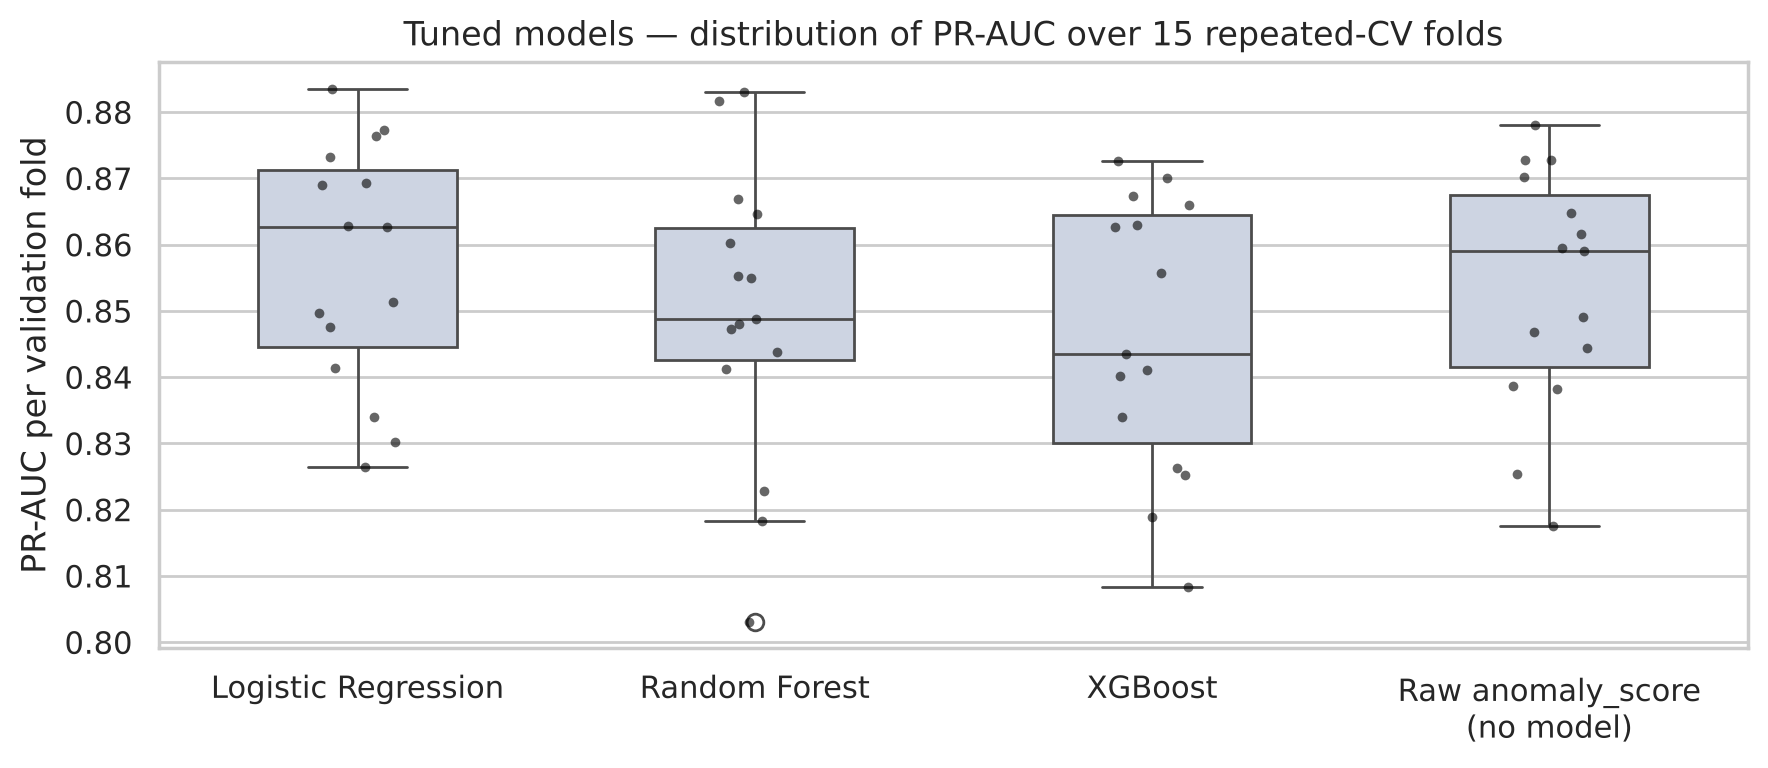

In [18]:
tuned = {name: rs.best_estimator_ for name, rs in searches.items()}
cmp_folds, cmp_summary = cv_table({k: clone(v) for k, v in tuned.items()}, X_dev, y_dev, cv=rcv, train_scores=True)
raw15 = raw_score_cv("anomaly_score", X_dev, y_dev, rcv)

cmp_view = cmp_summary[["pr_auc", "pr_auc_sd", "train_pr_auc", "roc_auc", "train_roc_auc", "recall", "precision", "f1", "brier"]].copy()
cmp_view.insert(3, "pr_auc_gap(train-cv)", cmp_view["train_pr_auc"] - cmp_view["pr_auc"])
cmp_view.loc["Raw anomaly_score ranking (no model)", ["pr_auc", "pr_auc_sd", "roc_auc"]] = [raw15.pr_auc.mean(), raw15.pr_auc.std(), raw15.roc_auc.mean()]
cmp_view.loc["No-skill (prevalence)", ["pr_auc", "roc_auc"]] = [y_dev.mean(), 0.5]
display(cmp_view)

names = list(tuned)
print("Paired comparisons on the 15 identical folds (PR-AUC):")
for a in range(len(names)):
    for b in range(a + 1, len(names)):
        d = cmp_folds[names[a]]["pr_auc"] - cmp_folds[names[b]]["pr_auc"]
        print(f"  {names[a]:>20s} − {names[b]:<20s}: mean diff {d.mean():+.4f} ± {d.std():.4f} | wins {(d > 0).sum()}/15")
d = cmp_folds["Logistic Regression"]["pr_auc"].values - raw15["pr_auc"].values
print(f"  {'Logistic Regression':>20s} − {'raw anomaly_score':<20s}: mean diff {d.mean():+.4f} ± {d.std():.4f} | wins {(d > 0).sum()}/15")

fig, ax = plt.subplots(figsize=(9, 4))
box = pd.DataFrame({**{n: cmp_folds[n]["pr_auc"] for n in names}, "Raw anomaly_score\n(no model)": raw15["pr_auc"]})
sns.boxplot(data=box, ax=ax, color="#C9D3E6", width=0.5); sns.stripplot(data=box, ax=ax, color="black", size=3.5, alpha=0.6)
ax.set_ylabel("PR-AUC per validation fold"); ax.set_title("Tuned models — distribution of PR-AUC over 15 repeated-CV folds")
plt.tight_layout(); plt.show()

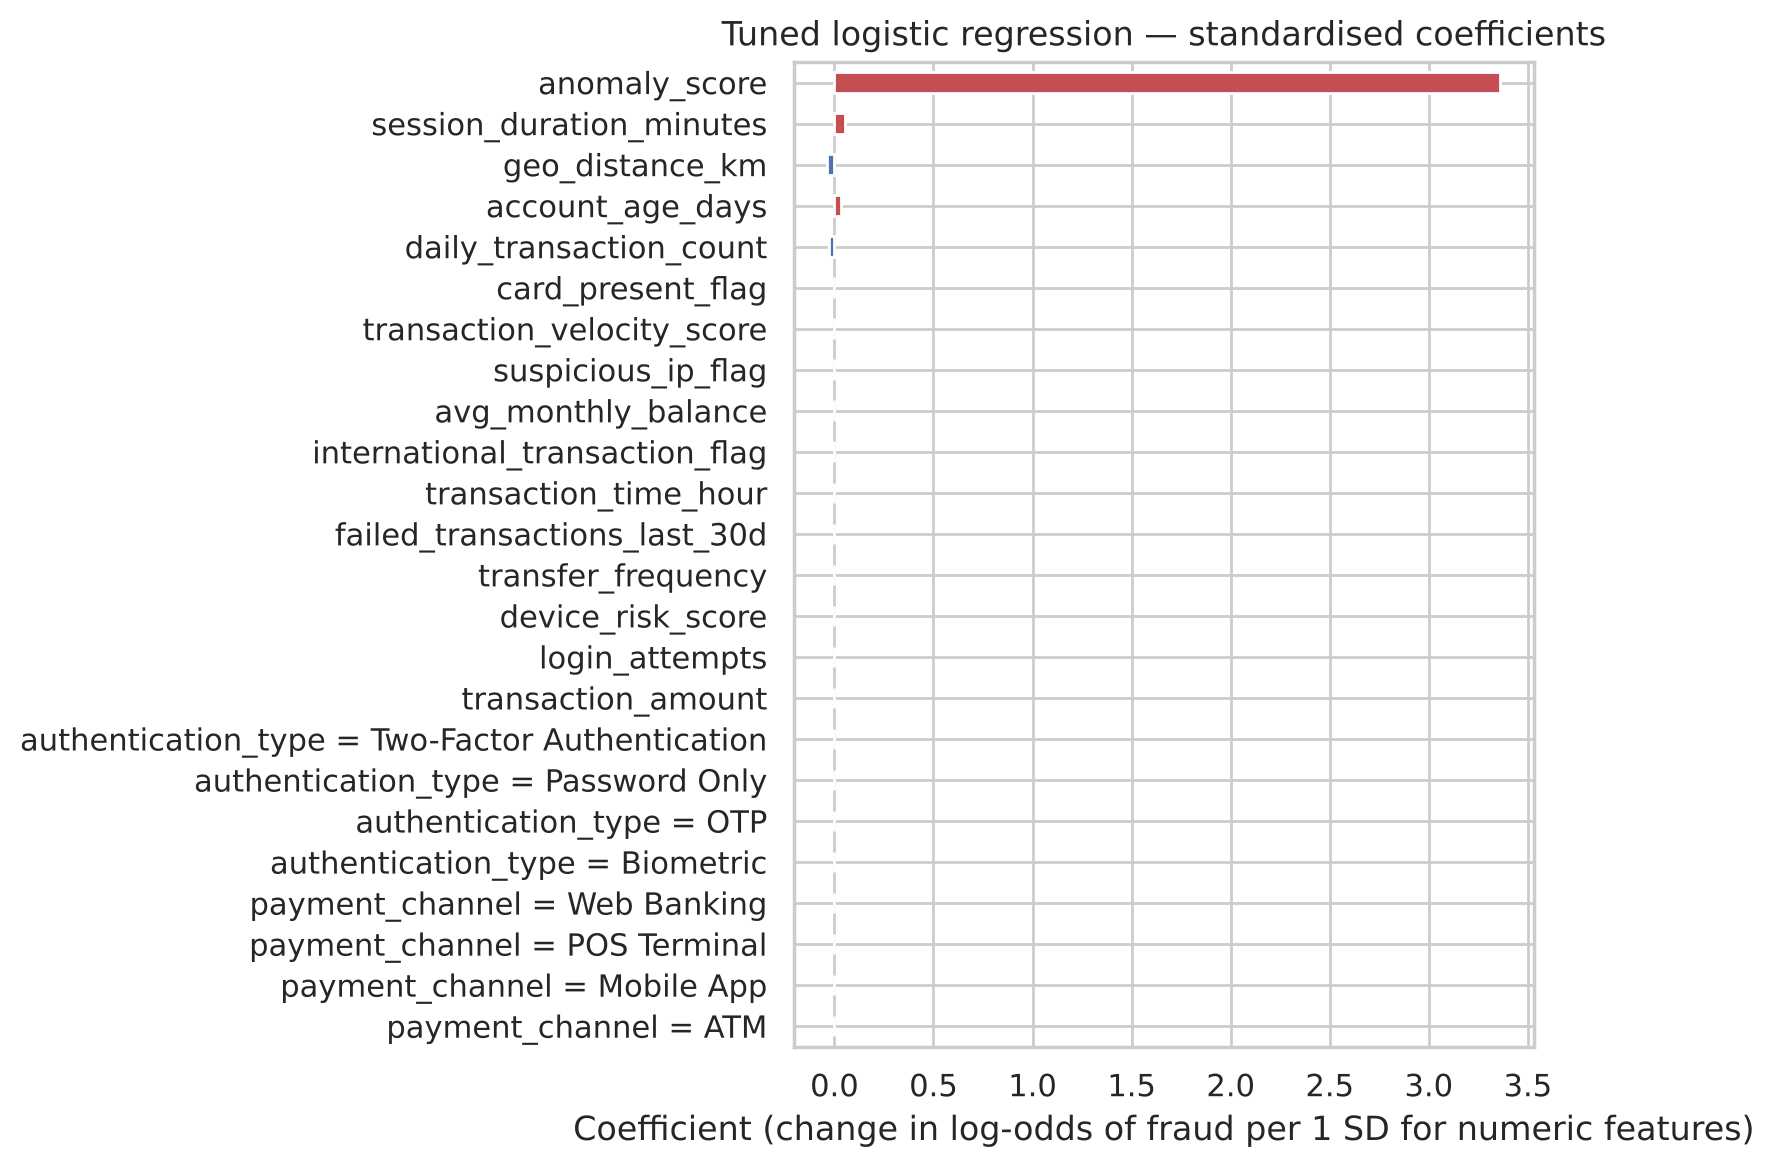

Non-zero coefficients: 5 of 24 | odds ratio per +1 SD of anomaly_score: 28.8


In [19]:
# Interpretable view of the tuned logistic regression (fitted on the full development set)
lr_fit = tuned["Logistic Regression"]
feat_names = [n.split("__")[-1] for n in lr_fit.named_steps["onehot"].get_feature_names_out()]
pre_names = NUM_COLS + BIN_COLS + CAT_COLS
cats = lr_fit.named_steps["preprocess"].named_transformers_["cat"].named_steps["ordinal"].categories_
readable = []
for n in feat_names:
    if n.startswith("x") and "_" in n and n.split("_")[0][1:].isdigit():          # one-hot output: x<idx>_<code>
        idx, code = int(n.split("_")[0][1:]), int(float(n.split("_")[1]))
        k = idx - len(NUM_COLS) - len(BIN_COLS)
        readable.append(f"{CAT_COLS[k]} = {cats[k][code]}")
    else:
        readable.append(pre_names[int(n[1:])] if n[1:].isdigit() else n)
coefs = pd.Series(lr_fit.named_steps["model"].coef_[0], index=readable)
coefs = coefs.reindex(coefs.abs().sort_values().index)
fig, ax = plt.subplots(figsize=(8, 6))
coefs.plot.barh(ax=ax, color=[C_FRAUD if v > 0 else C_LEGIT for v in coefs.values])
ax.set_xlabel("Coefficient (change in log-odds of fraud per 1 SD for numeric features)")
ax.set_title("Tuned logistic regression — standardised coefficients"); plt.tight_layout(); plt.show()
print(f"Non-zero coefficients: {(coefs != 0).sum()} of {len(coefs)} | odds ratio per +1 SD of anomaly_score: {np.exp(coefs['anomaly_score']):.1f}")

## 3.4 Model selection and discussion

**Tuning results**

- **Logistic regression** — best configuration: L1 penalty, strong regularisation (C ≈ 0.03), balanced class weights. The L1 penalty shrinks 19 of 24 coefficients to exactly zero; what remains is `anomaly_score` (odds ratio ≈ 29 per standard deviation) and four coefficients that are almost zero. The search found, on its own, the structure seen in the exploration.
- **Random forest / XGBoost** — the search consistently preferred the *most constrained* trees (forest: depth 5, ≥34 samples per leaf; XGBoost: depth-2 trees with a small learning rate). When hyperparameter search pushes flexible models towards their simplest settings, it signals that there is no complex structure to find. The tree models were also more sensitive to tuning (CV PR-AUC ranged 0.78–0.85 for the forest and 0.81–0.85 for XGBoost, against 0.84–0.86 for logistic regression).

**Comparison (15 repeated-CV folds)**

| | Logistic regression | Random forest | XGBoost |
|---|---|---|---|
| PR-AUC (mean ± SD) | **0.857 ± 0.018** | 0.849 ± 0.022 | 0.846 ± 0.021 |
| ROC-AUC | 0.977 | 0.976 | 0.976 |
| Train − CV gap in PR-AUC | **0.000** | 0.043 | 0.048 |
| Paired wins vs. logistic regression | — | 3 / 15 | 2 / 15 |

**Selected final model: L1-regularised logistic regression.** The reasons, in order of importance:

1. **It is at least as good on the primary metric.** It has the highest mean PR-AUC and wins 12–13 of 15 paired folds against each tree ensemble. The margins (0.008–0.011) are smaller than the fold-to-fold standard deviation, so the honest reading is "not worse", not "clearly better".
2. **It does not overfit.** Train and validation scores coincide, whereas both ensembles score 0.04–0.05 higher on the data they were trained on, and that extra fit does not transfer.
3. **When performance is tied, the simpler and more interpretable model is preferable** — it is easier to explain to regulators and customers, cheaper to monitor, and has fewer ways to fail silently.

**An uncomfortable but important observation.** The tuned logistic regression beats the *raw `anomaly_score` ranking* by only about 0.004 PR-AUC (consistent across 14 of 15 folds, but practically negligible). In ranking terms our "model" is close to a re-scaling of one input. Its practical contribution is the calibrated-to-a-threshold decision rule, not new discriminative power.

**Model assumptions and whether they hold**

- *Linearity of the log-odds.* Plausible here: the fraud rate rises monotonically and S-shaped with `anomaly_score`, which is the shape a logistic function produces. The tree models, which do not assume linearity, do not do better, which supports the assumption.
- *No interactions.* Not contradicted by the data: models that can learn interactions gain nothing.
- *Independent observations.* **Cannot be verified.** There is no customer or account ID; several transactions from one customer would be correlated and would make both CV and test estimates optimistic.
- *Stationarity.* Assumed by all three models and untestable without timestamps.

**Potential failure modes**

- *Single point of failure:* the model depends on one upstream feature. If `anomaly_score` is re-scaled, re-trained, delayed or missing, performance collapses (quantified in Sections 4.4 and 4.6). Median imputation would silently score a missing value as "average risk".
- *Evasion:* a fraudster who learns to keep the anomaly score under ~0.6 is invisible to this model.
- *Logistic regression specifically:* cannot represent a non-monotone or interaction-driven fraud pattern if one emerges later.
- *Tree ensembles specifically:* fit noise in the 17 uninformative features (the observed train–CV gap) and cannot extrapolate beyond the observed range.

**Trade-offs**

- *Interpretability vs. performance.* Usually a real tension; here there is none, because the interpretable model performs best. The trade-off would reappear if richer features were added.
- *Complexity vs. generalisation.* The ensembles' extra capacity is spent memorising noise. Given a fixed noise ceiling, added complexity only raises variance.
- *Ranking vs. calibration.* The search selected balanced class weights for logistic regression, although the PR-AUC advantage over unweighted training is within noise (Part 2: 0.001). The price is inflated probabilities (Brier ≈ 0.063 against ≈ 0.038 for unweighted models). The final model's output must therefore be read as a **risk score**, not as a literal probability; if calibrated probabilities are required, a prior-shift correction or isotonic recalibration is needed.

## 3.5 Choosing the operating threshold

The threshold is chosen on **out-of-fold predictions from the development set** (each prediction comes from a model that never saw that row), by maximising **F2**, which values recall twice as much as precision. The test set is not involved.

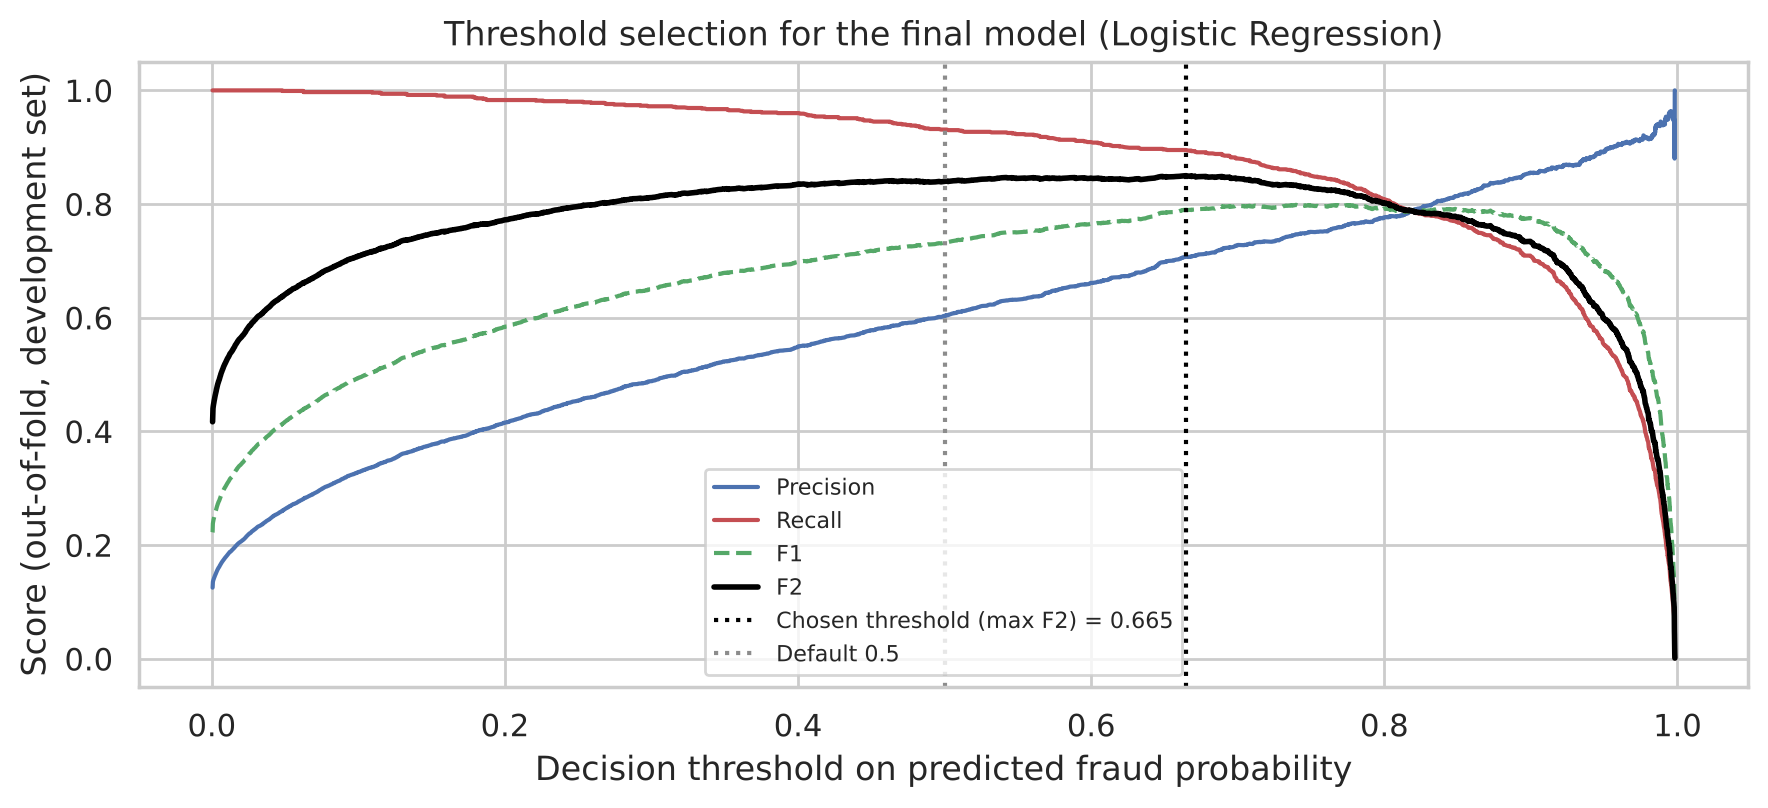

,precision,recall,f1,f2,flagged_%
default 0.50,0.6036,0.9311,0.7324,0.8399,19.3000
max-F1 (0.740),0.7470,0.8581,0.7987,0.8333,14.3750
max-F2 (0.665) <- chosen,0.7072,0.8951,0.7901,0.8499,15.8375


In [20]:
FINAL_NAME = "Logistic Regression"
final_model = clone(tuned[FINAL_NAME])

# Out-of-fold probabilities on the development set -> choose the operating threshold without touching the test set
oof_final = cross_val_predict(final_model, X_dev, y_dev, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_dev, oof_final)
f1_curve = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
f2_curve = 5 * prec[:-1] * rec[:-1] / np.clip(4 * prec[:-1] + rec[:-1], 1e-12, None)
THRESHOLD = float(thr[np.argmax(f2_curve)])
T_F1 = float(thr[np.argmax(f1_curve)])

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(thr, prec[:-1], label="Precision", color=C_LEGIT); ax.plot(thr, rec[:-1], label="Recall", color=C_FRAUD)
ax.plot(thr, f1_curve, label="F1", color="#55A868", ls="--"); ax.plot(thr, f2_curve, label="F2", color="black", lw=2)
ax.axvline(THRESHOLD, color="black", ls=":", label=f"Chosen threshold (max F2) = {THRESHOLD:.3f}")
ax.axvline(0.5, color=C_NEUTRAL, ls=":", label="Default 0.5")
ax.set_xlabel("Decision threshold on predicted fraud probability"); ax.set_ylabel("Score (out-of-fold, development set)")
ax.set_title(f"Threshold selection for the final model ({FINAL_NAME})"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

def metrics_at(y_true, proba, t):
    pred = (proba >= t).astype(int)
    return {"precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred), "f2": fbeta_score(y_true, pred, beta=2), "flagged_%": pred.mean() * 100}
display(pd.DataFrame({f"default 0.50": metrics_at(y_dev, oof_final, 0.5), f"max-F1 ({T_F1:.3f})": metrics_at(y_dev, oof_final, T_F1),
                      f"max-F2 ({THRESHOLD:.3f})  <- chosen": metrics_at(y_dev, oof_final, THRESHOLD)}).T)

**Chosen threshold ≈ 0.665** on the model's score scale (higher than 0.5 because balanced class weights inflate the scores). On out-of-fold development data it gives recall ≈ 0.90 and precision ≈ 0.71 while flagging about 16% of transactions.

Two remarks. First, the F2 curve is nearly flat between roughly 0.5 and 0.75 (F2 between 0.83 and 0.85), so the exact value is not critical and its location is only loosely determined by the data — this is examined in Section 4.4. Second, because the model is dominated by one feature, this threshold is nearly equivalent to the rule *"flag when `anomaly_score` is above roughly 0.6"*, as the error analysis in Section 4.3 confirms.

---
# Part 4 — Model Evaluation & Analytical Depth

## 4.1 Final evaluation on the held-out test set

The final pipeline is re-fit on the **entire development set** and evaluated **once** on the 2,000 test transactions that have not influenced any decision so far.

,PR-AUC,ROC-AUC,Precision,Recall,F1,F2,Brier
"Train (development, in-sample)",0.8567,0.9771,0.7085,0.8911,0.7894,0.8474,0.0617
Cross-validation (out-of-fold),0.8554,0.9769,0.7072,0.8951,0.7901,0.8499,0.0626
Test (held-out),0.8816,0.9802,0.7179,0.8960,0.7972,0.8537,0.0579


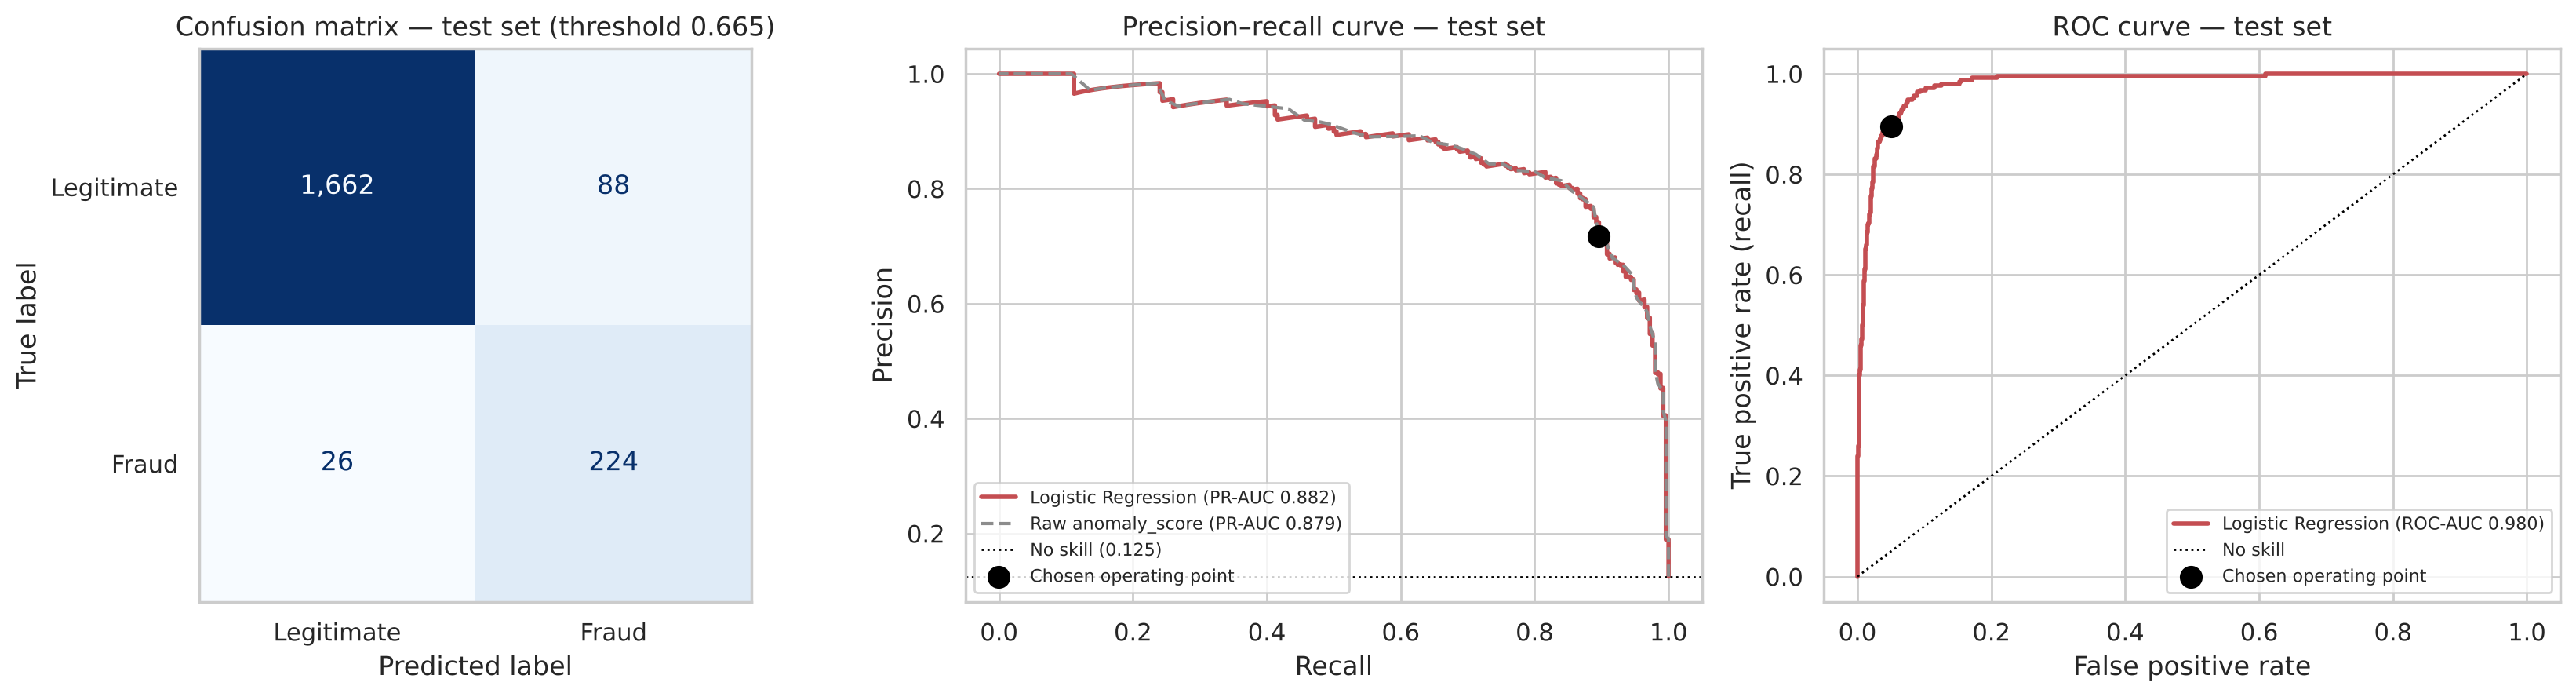

Test set: 2,000 transactions, 250 frauds.
  True positives  (fraud caught)        :  224   -> recall    = 89.6%
  False negatives (fraud missed)        :   26
  False positives (false alarms)        :   88   -> precision = 71.8%; 5.0% of legitimate customers flagged
  True negatives  (correctly cleared)   : 1662
  Alerts raised: 312 (15.6% of all transactions); 0.39 false alarms per fraud caught


In [21]:
final_model.fit(X_dev, y_dev)
p_train = final_model.predict_proba(X_dev)[:, 1]
p_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (p_test >= THRESHOLD).astype(int)

def full_report(y_true, proba, t):
    return {"PR-AUC": average_precision_score(y_true, proba), "ROC-AUC": roc_auc_score(y_true, proba),
            **{k.capitalize(): v for k, v in metrics_at(y_true, proba, t).items() if k != "flagged_%"},
            "Brier": brier_score_loss(y_true, proba)}

perf = pd.DataFrame({"Train (development, in-sample)": full_report(y_dev, p_train, THRESHOLD),
                     "Cross-validation (out-of-fold)": full_report(y_dev, oof_final, THRESHOLD),
                     "Test (held-out)": full_report(y_test, p_test, THRESHOLD)}).T
display(perf)

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["Legitimate", "Fraud"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format=",d")
axes[0].set_title(f"Confusion matrix — test set (threshold {THRESHOLD:.3f})"); axes[0].grid(False)

pt, rt, _ = precision_recall_curve(y_test, p_test)
axes[1].plot(rt, pt, color=C_FRAUD, lw=2, label=f"{FINAL_NAME} (PR-AUC {average_precision_score(y_test, p_test):.3f})")
pr_, rr_, _ = precision_recall_curve(y_test, X_test["anomaly_score"])
axes[1].plot(rr_, pr_, color=C_NEUTRAL, lw=1.5, ls="--", label=f"Raw anomaly_score (PR-AUC {average_precision_score(y_test, X_test['anomaly_score']):.3f})")
axes[1].axhline(y_test.mean(), color="black", ls=":", lw=1, label=f"No skill ({y_test.mean():.3f})")
axes[1].scatter(tp / (tp + fn), tp / (tp + fp), s=90, color="black", zorder=5, label="Chosen operating point")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–recall curve — test set"); axes[1].legend(fontsize=8, loc="lower left")

f_, t_, _ = roc_curve(y_test, p_test)
axes[2].plot(f_, t_, color=C_FRAUD, lw=2, label=f"{FINAL_NAME} (ROC-AUC {roc_auc_score(y_test, p_test):.3f})")
axes[2].plot([0, 1], [0, 1], color="black", ls=":", lw=1, label="No skill")
axes[2].scatter(fp / (fp + tn), tp / (tp + fn), s=90, color="black", zorder=5, label="Chosen operating point")
axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate (recall)"); axes[2].set_title("ROC curve — test set"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Test set: {len(y_test):,} transactions, {y_test.sum()} frauds.")
print(f"  True positives  (fraud caught)        : {tp:4d}   -> recall    = {tp/(tp+fn):.1%}")
print(f"  False negatives (fraud missed)        : {fn:4d}")
print(f"  False positives (false alarms)        : {fp:4d}   -> precision = {tp/(tp+fp):.1%}; {fp/(fp+tn):.1%} of legitimate customers flagged")
print(f"  True negatives  (correctly cleared)   : {tn:4d}")
print(f"  Alerts raised: {tp+fp} ({(tp+fp)/len(y_test):.1%} of all transactions); {fp/max(tp,1):.2f} false alarms per fraud caught")

**Interpretation of the test results**

- **Ranking quality.** PR-AUC ≈ 0.88 against a no-skill value of 0.125, ROC-AUC ≈ 0.98. The model's PR curve is indistinguishable from that of the raw `anomaly_score`.
- **Confusion matrix.** Of 250 frauds, **224 are caught and 26 are missed** (recall 89.6%). The price is **88 false alarms** among 1,750 legitimate transactions (5.0%). An analyst reviewing the 312 alerts finds a real fraud in about 7 of every 10 (precision 71.8%), i.e. roughly 0.4 false alarms per fraud caught. In total 15.6% of transactions are flagged, a workload that is only acceptable if most alerts are handled automatically (e.g. step-up authentication) rather than by manual review.
- **Which error matters more?** The 26 missed frauds are direct losses; the 88 false alarms are friction. Whether this balance is right depends on the bank's cost ratio (Section 4.5).
- **The threshold transfers.** Precision and recall on the test set (0.718 / 0.896) are almost identical to the out-of-fold development values (0.707 / 0.895). The operating point chosen without the test set behaves as predicted on it.
- **Test PR-AUC (0.882) is higher than the CV estimate (0.855).** This should not be read as "the model does better on new data". Individual CV folds ranged from 0.83 to 0.88, and the bootstrap interval in Section 4.4 is wide; this particular test split is simply on the favourable side of sampling variation.

## 4.2 Bias–variance diagnosis

Two tools: (a) the train / cross-validation / test comparison in the table above, and (b) a **learning curve** — PR-AUC on training and validation folds as the training set grows.

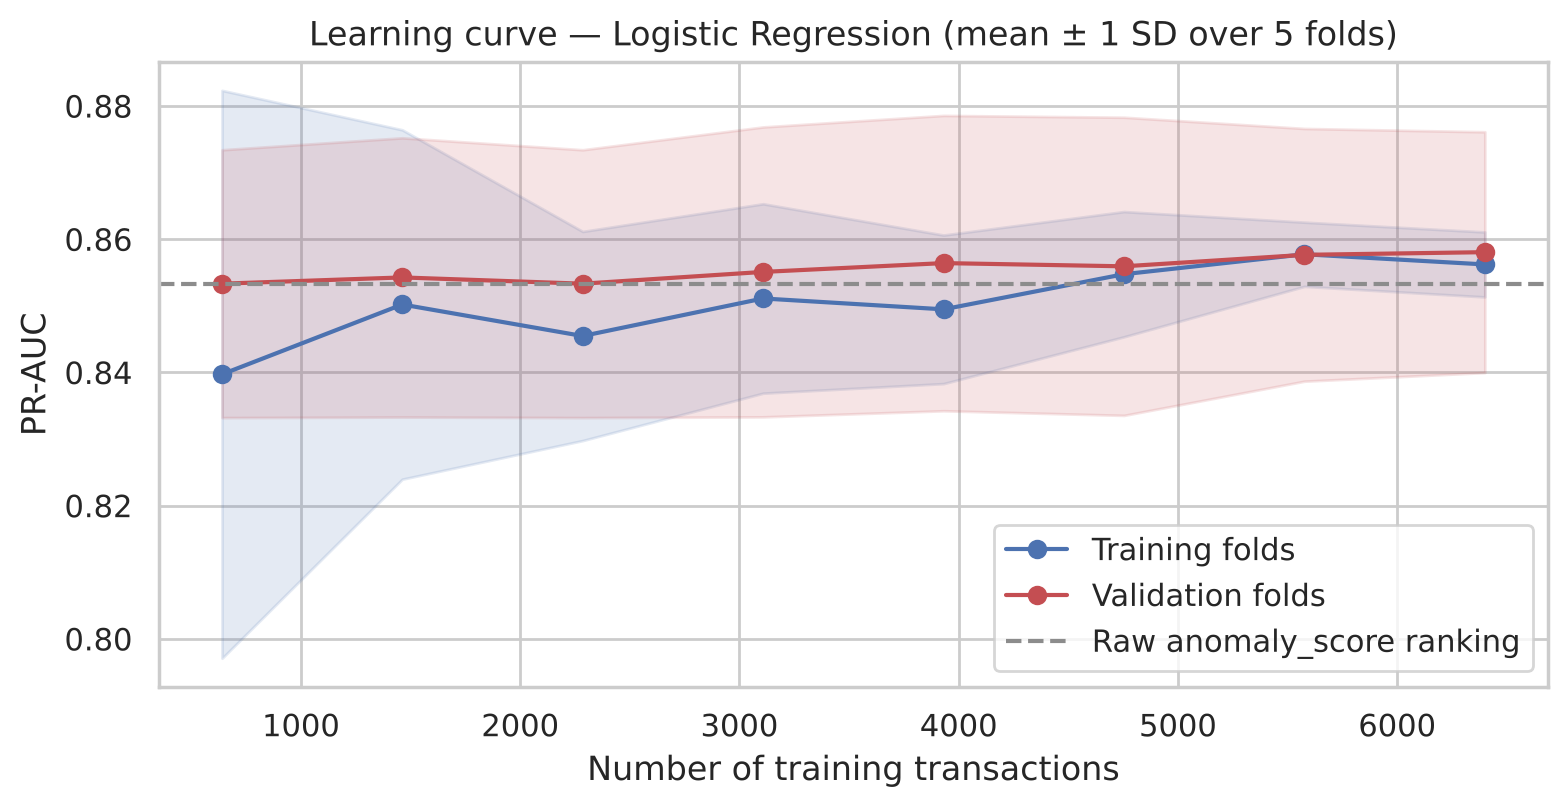

 n_train  train_pr_auc  val_pr_auc     gap
     640        0.8397      0.8533 -0.0136
    1462        0.8502      0.8543 -0.0041
    2285        0.8455      0.8533 -0.0079
    3108        0.8511      0.8551 -0.0040
    3931        0.8495      0.8564 -0.0069
    4754        0.8547      0.8559 -0.0012
    5577        0.8577      0.8576  0.0001
    6400        0.8562      0.8580 -0.0018


In [22]:
sizes, tr_sc, va_sc = learning_curve(clone(final_model), X_dev, y_dev, cv=cv5, scoring="average_precision",
                                     train_sizes=np.linspace(0.1, 1.0, 8), n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 4.2))
for sc_, lab, col in [(tr_sc, "Training folds", C_LEGIT), (va_sc, "Validation folds", C_FRAUD)]:
    ax.plot(sizes, sc_.mean(1), marker="o", color=col, label=lab)
    ax.fill_between(sizes, sc_.mean(1) - sc_.std(1), sc_.mean(1) + sc_.std(1), color=col, alpha=0.15)
ax.axhline(raw15.pr_auc.mean(), color=C_NEUTRAL, ls="--", label="Raw anomaly_score ranking")
ax.set_xlabel("Number of training transactions"); ax.set_ylabel("PR-AUC"); ax.set_title(f"Learning curve — {FINAL_NAME} (mean ± 1 SD over 5 folds)")
ax.legend(); plt.tight_layout(); plt.show()
print(pd.DataFrame({"n_train": sizes, "train_pr_auc": tr_sc.mean(1), "val_pr_auc": va_sc.mean(1), "gap": tr_sc.mean(1) - va_sc.mean(1)}).round(4).to_string(index=False))

**Diagnosis**

- **Variance is negligible.** Training, cross-validation and test scores agree (PR-AUC 0.857 / 0.855 / 0.882; precision and recall within 0.01 of each other), and the learning curve shows training and validation scores meeting almost immediately. A model with five effective parameters fitted on 8,000 rows has very little capacity to overfit.
- **More data would not help.** Validation PR-AUC is already ≈ 0.853 with 640 training rows and ≈ 0.858 with 6,400. The curve is flat: the model has learned everything it can from these features.
- **Is the remaining error "bias"?** Not in the usual sense of an under-powered model. If logistic regression were too simple, more flexible learners would score higher on validation data; they do not (Section 3.3), they only score higher on *training* data. The residual error is therefore best described as **irreducible noise given the available features**: in the 0.5–0.75 `anomaly_score` zone the label is close to a coin flip that no function of these inputs can predict.
- **Consequence.** Neither a more complex model (reduces bias) nor more rows or regularisation (reduce variance) will move the result. Only *new information* — additional features that discriminate within the overlap zone — can.

## 4.3 Error analysis

We examine *which* transactions the model gets wrong on the test set, and whether errors concentrate in particular segments.

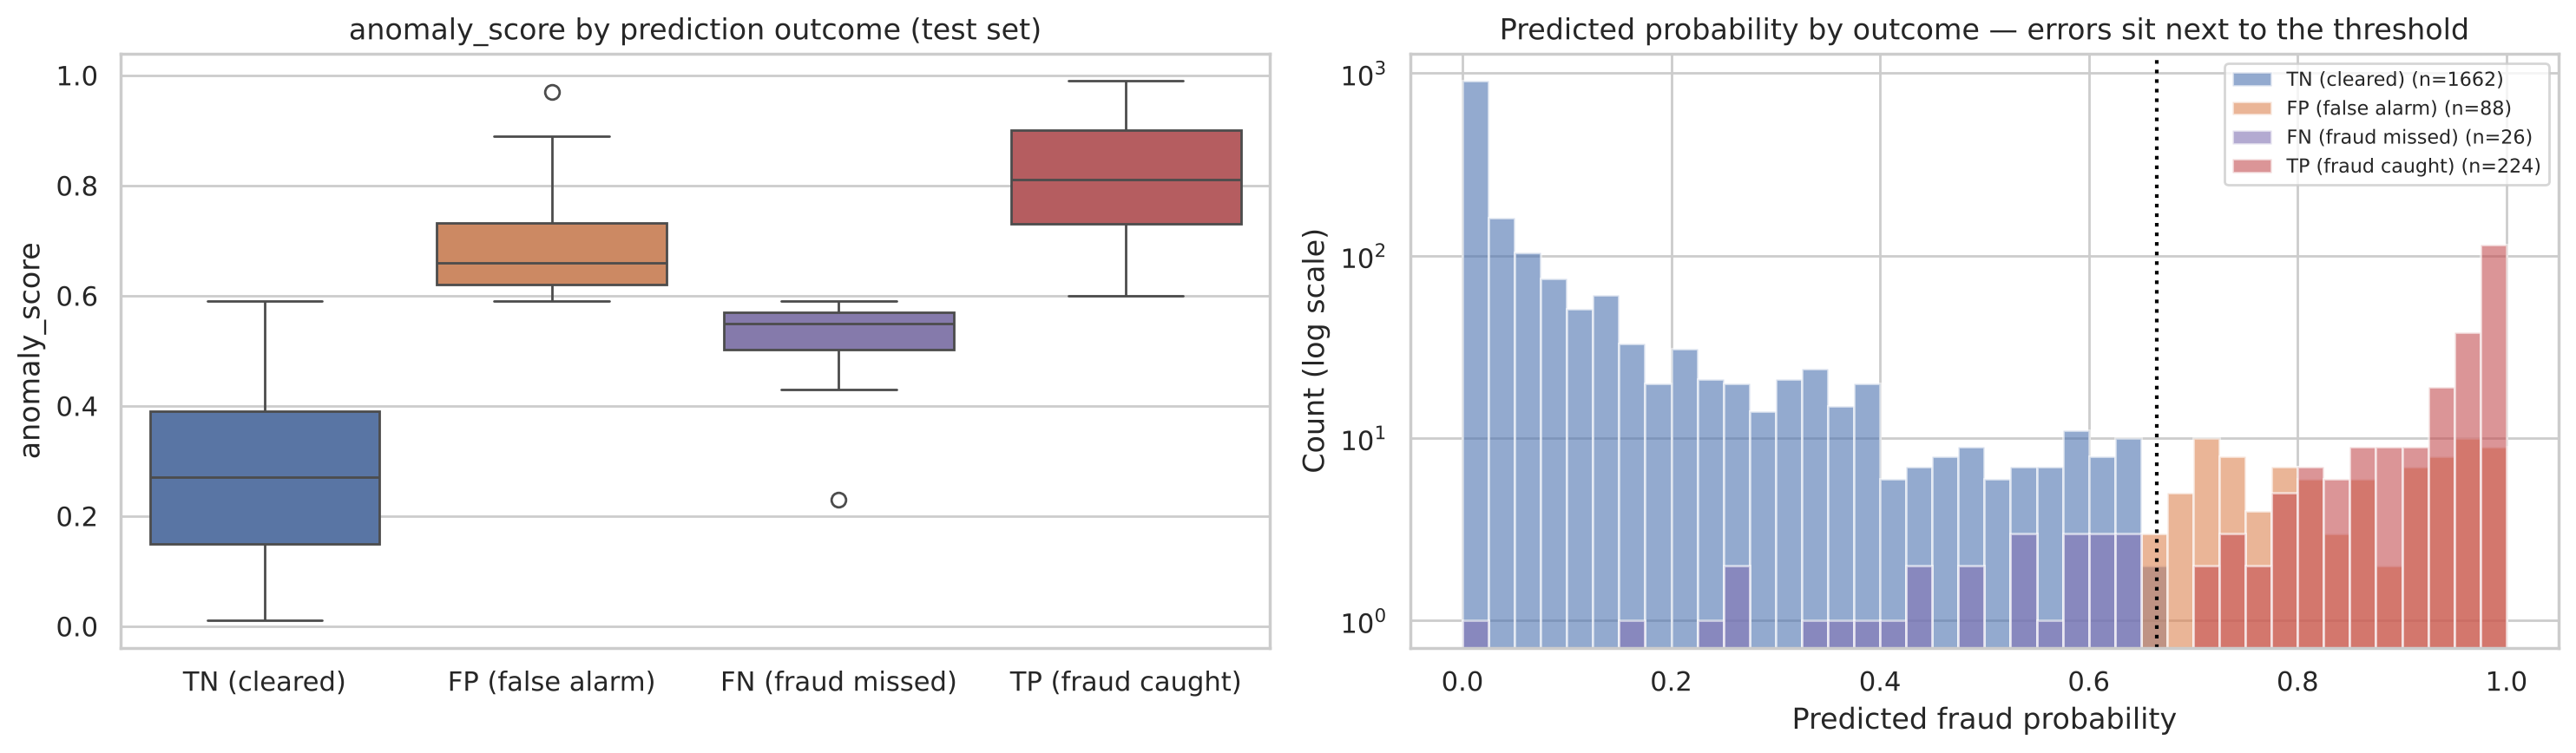

Median feature values by outcome (test set):


outcome,TN (cleared),FP (false alarm),FN (fraud missed),TP (fraud caught)
transaction_amount,"12,413.7500","11,650.4000","13,210.2800","11,914.3250"
login_attempts,6.0000,7.0000,6.0000,8.0000
device_risk_score,50.0500,56.1500,45.8500,51.7500
transfer_frequency,39.0000,49.0000,35.5000,42.0000
anomaly_score,0.2700,0.6600,0.5500,0.8100
account_age_days,"2,645.0000","2,690.5000","2,031.0000","2,535.0000"
transaction_time_hour,11.0000,12.0000,11.5000,11.0000
failed_transactions_last_30d,13.0000,14.0000,16.0000,12.0000
avg_monthly_balance,"255,950.6550","217,691.6850","289,207.2850","263,204.3850"
daily_transaction_count,60.0000,61.5000,70.0000,60.5000


Mann-Whitney tests on the 15 non-anomaly features — smallest p-values (Bonferroni threshold = 0.0017):


,FN vs TP (p),FP vs TN (p),min_p
feature,,,
login_attempts,0.0220,0.9807,0.0220
transfer_frequency,0.3569,0.0516,0.0516
transaction_velocity_score,0.9589,0.0575,0.0575
session_duration_minutes,0.8042,0.1259,0.1259
card_present_flag,0.1275,0.2547,0.1275


In [23]:
err = X_test.copy()
err["y"], err["proba"], err["pred"] = y_test.values, p_test, pred_test
err["outcome"] = np.select([(err.y == 1) & (err.pred == 1), (err.y == 1) & (err.pred == 0), (err.y == 0) & (err.pred == 1)],
                           ["TP (fraud caught)", "FN (fraud missed)", "FP (false alarm)"], default="TN (cleared)")
order4 = ["TN (cleared)", "FP (false alarm)", "FN (fraud missed)", "TP (fraud caught)"]
pal = {"TN (cleared)": C_LEGIT, "FP (false alarm)": "#DD8452", "FN (fraud missed)": "#8172B3", "TP (fraud caught)": C_FRAUD}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=err, x="outcome", y="anomaly_score", order=order4, palette=pal, ax=axes[0])
axes[0].set_title("anomaly_score by prediction outcome (test set)"); axes[0].set_xlabel("")
for o in order4:
    axes[1].hist(err.loc[err.outcome == o, "proba"], bins=np.linspace(0, 1, 41), alpha=0.6, color=pal[o], label=f"{o} (n={(err.outcome == o).sum()})")
axes[1].axvline(THRESHOLD, color="black", ls=":"); axes[1].set_yscale("log")
axes[1].set_xlabel("Predicted fraud probability"); axes[1].set_ylabel("Count (log scale)"); axes[1].legend(fontsize=8)
axes[1].set_title("Predicted probability by outcome — errors sit next to the threshold")
plt.tight_layout(); plt.show()

print("Median feature values by outcome (test set):")
display(err.groupby("outcome")[NUM_COLS].median().loc[order4].T)

# Do the errors differ from the correct predictions on anything other than anomaly_score?
rows = []
for c in [c for c in NUM_COLS + BIN_COLS if c != "anomaly_score"]:
    fn_p = stats.mannwhitneyu(err.loc[err.outcome == "FN (fraud missed)", c], err.loc[err.outcome == "TP (fraud caught)", c]).pvalue
    fp_p = stats.mannwhitneyu(err.loc[err.outcome == "FP (false alarm)", c], err.loc[err.outcome == "TN (cleared)", c]).pvalue
    rows.append({"feature": c, "FN vs TP (p)": fn_p, "FP vs TN (p)": fp_p})
mw = pd.DataFrame(rows).set_index("feature")
print(f"Mann-Whitney tests on the {len(mw)} non-anomaly features — smallest p-values (Bonferroni threshold = {0.05 / (2 * len(mw)):.4f}):")
display(mw.assign(min_p=mw.min(axis=1)).sort_values("min_p").head(5))

In [24]:
# Segment-level performance: is the model equally reliable across channels and authentication types?
def segment_table(col):
    rows = []
    for level, g in err.groupby(col):
        rows.append({col: level, "n": len(g), "frauds": int(g.y.sum()), "fraud_rate": g.y.mean(),
                     "recall": recall_score(g.y, g.pred), "precision": precision_score(g.y, g.pred, zero_division=0),
                     "false_alarm_rate": ((g.y == 0) & (g.pred == 1)).sum() / max((g.y == 0).sum(), 1),
                     "pr_auc": average_precision_score(g.y, g.proba)})
    return pd.DataFrame(rows).set_index(col)
for c in CAT_COLS + ["international_transaction_flag"]:
    display(segment_table(c))

# Errors as a function of the anomaly score band
err["anomaly_band"] = pd.cut(err["anomaly_score"], [0, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0], include_lowest=True)
band = err.groupby("anomaly_band", observed=True).agg(n=("y", "size"), fraud_rate=("y", "mean"), flagged_rate=("pred", "mean"),
        FN=("outcome", lambda s: (s == "FN (fraud missed)").sum()), FP=("outcome", lambda s: (s == "FP (false alarm)").sum()))
band["share_of_all_errors"] = (band.FN + band.FP) / (band.FN + band.FP).sum()
display(band)

,n,frauds,fraud_rate,recall,precision,false_alarm_rate,pr_auc
payment_channel,,,,,,,
ATM,158,14,0.0886,0.9286,0.7222,0.0347,0.7403
Mobile App,961,134,0.1394,0.8806,0.7152,0.0568,0.8696
POS Terminal,241,34,0.1411,0.8529,0.7838,0.0386,0.9070
Web Banking,640,68,0.1062,0.9412,0.6957,0.0490,0.9242


,n,frauds,fraud_rate,recall,precision,false_alarm_rate,pr_auc
authentication_type,,,,,,,
Biometric,333,39,0.1171,0.8462,0.7174,0.0442,0.8636
OTP,849,115,0.1355,0.8957,0.7574,0.0450,0.8647
Password Only,348,47,0.1351,0.9149,0.6825,0.0664,0.9150
Two-Factor Authentication,470,49,0.1043,0.9184,0.6716,0.0523,0.9083


,n,frauds,fraud_rate,recall,precision,false_alarm_rate,pr_auc
international_transaction_flag,,,,,,,
0,984,132,0.1341,0.9015,0.7438,0.0481,0.8821
1,1016,118,0.1161,0.8898,0.6908,0.0523,0.8839


,n,fraud_rate,flagged_rate,FN,FP,share_of_all_errors
anomaly_band,,,,,,
"(-0.001, 0.4]",1298,0.0008,0.0000,1,0,0.0088
"(0.4, 0.5]",269,0.0223,0.0000,6,0,0.0526
"(0.5, 0.6]",132,0.1515,0.0833,19,10,0.2544
"(0.6, 0.7]",94,0.4787,1.0000,0,49,0.4298
"(0.7, 0.8]",83,0.7711,1.0000,0,19,0.1667
"(0.8, 1.0]",124,0.9194,1.0000,0,10,0.0877


**What the errors have in common**

- **Errors are confined to the overlap zone.** Every false alarm has `anomaly_score` ≥ 0.59 and all but one missed fraud lie between 0.4 and 0.6 (the exception is a fraud with a score of 0.23 — undetectable with these features). About 85% of all errors fall in the 0.5–0.8 band, which contains only 15% of transactions.
- **False alarms (88).** More than half (49) are in the 0.6–0.7 band, where the true fraud rate is about 48%: the model flags everything there, and is wrong half of the time by construction. Ten false alarms have scores above 0.8, where 92% of transactions are fraud; these are either genuinely unusual legitimate transactions or mislabelled frauds.
- **Missed frauds (26).** Nineteen sit in the 0.5–0.6 band, where only 15% of transactions are fraud. Catching them would require flagging the whole band, i.e. roughly five to six additional false alarms per extra fraud caught.
- **No other feature distinguishes errors from correct predictions.** Comparing missed with caught frauds, and false alarms with correctly cleared transactions, on the 15 other features gives no difference that survives a multiple-testing correction (smallest p ≈ 0.02 against a Bonferroni threshold of 0.0017). The differences in medians visible in the table (e.g. account age, login attempts) are what 30 comparisons on small groups produce by chance. There is no overlooked "second signal" that a better model could exploit.
- **Segments.** Recall ranges from about 0.85 to 0.94 across payment channels and authentication types, and the false-alarm rate from 3.5% to 6.6%. With only 14–134 frauds per segment, these differences are within sampling noise (the low PR-AUC for ATM rests on 14 frauds), and they do not follow a consistent pattern. There is no evidence that the model is systematically weaker for one channel — but also not enough data to rule it out.

**Summary:** the model fails where the input data are ambiguous, not where the model is mis-specified. The errors are structural, and they would be reproduced by any classifier trained on these features.

## 4.4 Robustness

Four checks: (a) stability across repeated CV folds, (b) bootstrap confidence intervals on the test set, (c) sensitivity to the random seed of the split, (d) sensitivity to measurement noise in the dominant feature.

In [25]:
# (a) Cross-validation stability (15 folds)
stab = cmp_folds[FINAL_NAME][["pr_auc", "roc_auc", "recall", "precision", "f1"]]
stab_tbl = stab.agg(["mean", "std", "min", "max"]).T
stab_tbl["cv_%"] = stab_tbl["std"] / stab_tbl["mean"] * 100
print("(a) Repeated stratified CV, 5 x 3 folds (recall/precision/F1 at the default 0.5 threshold):"); display(stab_tbl)

# (b) Bootstrap 95% confidence intervals on the test set
rng = np.random.default_rng(RANDOM_STATE)
yt, boots = y_test.values, []
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0: continue
    boots.append({"PR-AUC": average_precision_score(yt[i], p_test[i]), "ROC-AUC": roc_auc_score(yt[i], p_test[i]),
                  "Precision": precision_score(yt[i], pred_test[i], zero_division=0), "Recall": recall_score(yt[i], pred_test[i]),
                  "F2": fbeta_score(yt[i], pred_test[i], beta=2),
                  "PR-AUC gain vs raw anomaly_score": average_precision_score(yt[i], p_test[i]) - average_precision_score(yt[i], X_test["anomaly_score"].values[i])})
boots = pd.DataFrame(boots)
ci = pd.DataFrame({"point estimate": [perf.loc["Test (held-out)", c] if c in perf.columns else
                                      average_precision_score(y_test, p_test) - average_precision_score(y_test, X_test["anomaly_score"]) for c in boots.columns],
                   "2.5%": boots.quantile(0.025).values, "97.5%": boots.quantile(0.975).values}, index=boots.columns)
print("(b) Test-set bootstrap (1,000 resamples), 95% confidence intervals:"); display(ci)

(a) Repeated stratified CV, 5 x 3 folds (recall/precision/F1 at the default 0.5 threshold):


,mean,std,min,max,cv_%
pr_auc,0.8570,0.0183,0.8265,0.8835,2.1409
roc_auc,0.9769,0.0025,0.9729,0.9809,0.2601
recall,0.9314,0.0145,0.9055,0.9502,1.5583
precision,0.6060,0.0212,0.5745,0.6514,3.4922
f1,0.7340,0.0154,0.7088,0.7629,2.0960


(b) Test-set bootstrap (1,000 resamples), 95% confidence intervals:


,point estimate,2.5%,97.5%
PR-AUC,0.8816,0.8411,0.9153
ROC-AUC,0.9802,0.9728,0.9861
Precision,0.7179,0.6656,0.7695
Recall,0.8960,0.8554,0.9328
F2,0.8537,0.8188,0.8855
PR-AUC gain vs raw anomaly_score,0.0023,0.0006,0.0042


(c) Alternative split seeds (hyperparameters fixed; sensitivity analysis only, not used for any decision):


,threshold,PR-AUC,ROC-AUC,precision,recall,f2
0,0.6817,0.8602,0.9770,0.7205,0.8560,0.8250
1,0.6475,0.8948,0.9805,0.7147,0.9120,0.8643
2,0.5415,0.8331,0.9747,0.6356,0.9000,0.8309
3,0.6646,0.8622,0.9801,0.7365,0.8720,0.8410
4,0.5601,0.8520,0.9790,0.6356,0.9280,0.8498
5,0.6745,0.8773,0.9799,0.7110,0.8760,0.8372
6,0.6919,0.8458,0.9749,0.6894,0.8880,0.8396
7,0.5965,0.8692,0.9808,0.6619,0.9320,0.8617
mean,0.6323,0.8618,0.9784,0.6882,0.8955,0.8437
std,0.0583,0.0191,0.0025,0.0393,0.0273,0.0140


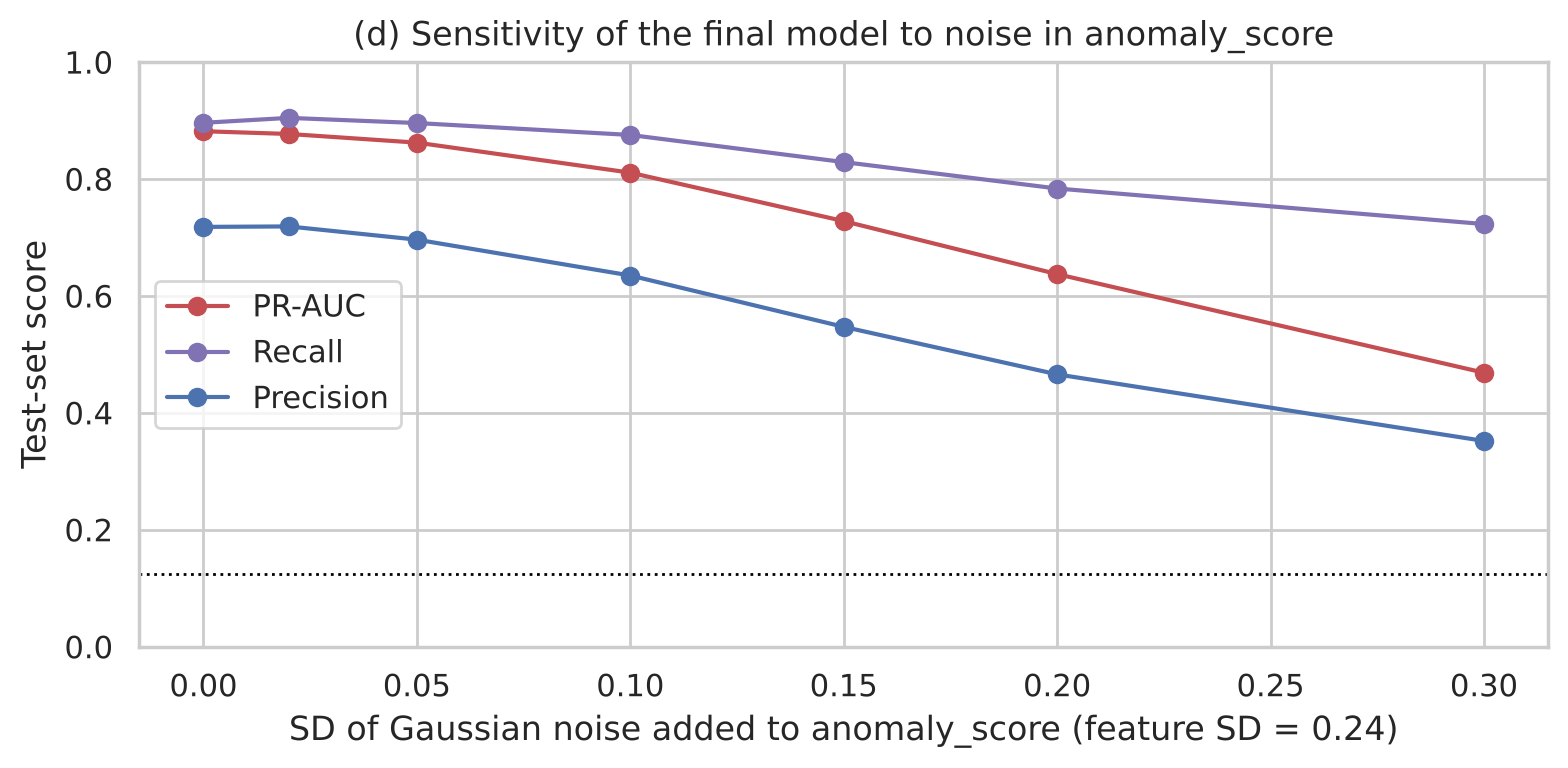

,PR-AUC,Recall,Precision
noise_sd,,,
0.0000,0.8816,0.8960,0.7179
0.0200,0.8769,0.9044,0.7187
0.0500,0.8621,0.8956,0.6961
0.1000,0.8107,0.8752,0.6348
0.1500,0.7278,0.8288,0.5469
0.2000,0.6372,0.7836,0.4657
0.3000,0.4685,0.7228,0.3518


In [26]:
# (c) Sensitivity to the train/test split seed: repeat the whole fit -> threshold -> test procedure with other seeds
rows = []
for seed in [0, 1, 2, 3, 4, 5, 6, 7]:
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.20, stratify=y, random_state=seed)
    m = clone(final_model)
    o = cross_val_predict(m, Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="predict_proba", n_jobs=-1)[:, 1]
    pr_, rc_, th_ = precision_recall_curve(ya, o)
    t_ = th_[np.argmax(5 * pr_[:-1] * rc_[:-1] / np.clip(4 * pr_[:-1] + rc_[:-1], 1e-12, None))]
    pb = m.fit(Xa, ya).predict_proba(Xb)[:, 1]
    rows.append({"seed": seed, "threshold": t_, "PR-AUC": average_precision_score(yb, pb), "ROC-AUC": roc_auc_score(yb, pb),
                 **{k: v for k, v in metrics_at(yb, pb, t_).items() if k in ("precision", "recall", "f2")}})
seed_tbl = pd.DataFrame(rows).set_index("seed")
print("(c) Alternative split seeds (hyperparameters fixed; sensitivity analysis only, not used for any decision):")
display(pd.concat([seed_tbl, seed_tbl.agg(["mean", "std"])]))

# (d) Sensitivity to noise in anomaly_score at inference time
noise_rows = []
for sd in [0, 0.02, 0.05, 0.10, 0.15, 0.20, 0.30]:
    vals = []
    for rep in range(10):
        Xn = X_test.copy()
        Xn["anomaly_score"] = np.clip(Xn["anomaly_score"] + np.random.default_rng(rep).normal(0, sd, len(Xn)), 0, 1)
        pn = final_model.predict_proba(Xn)[:, 1]
        vals.append([average_precision_score(y_test, pn), recall_score(y_test, pn >= THRESHOLD), precision_score(y_test, pn >= THRESHOLD)])
    noise_rows.append([sd, *np.mean(vals, 0)])
noise = pd.DataFrame(noise_rows, columns=["noise_sd", "PR-AUC", "Recall", "Precision"]).set_index("noise_sd")
fig, ax = plt.subplots(figsize=(8, 4))
noise.plot(ax=ax, marker="o", color=[C_FRAUD, "#8172B3", C_LEGIT])
ax.axhline(y_test.mean(), color="black", ls=":", lw=1); ax.set_ylim(0, 1)
ax.set_xlabel(f"SD of Gaussian noise added to anomaly_score (feature SD = {X_dev['anomaly_score'].std():.2f})"); ax.set_ylabel("Test-set score")
ax.set_title("(d) Sensitivity of the final model to noise in anomaly_score"); plt.tight_layout(); plt.show()
display(noise)

**Robustness findings**

- **(a) Cross-validation stability.** PR-AUC = 0.857 ± 0.018 over 15 folds (range 0.83–0.88, coefficient of variation ≈ 2%); ROC-AUC varies by only ± 0.003. PR-AUC is noisier because each validation fold has only ~200 frauds.
- **(b) Uncertainty of the test estimate.** 95% bootstrap intervals: PR-AUC 0.84–0.92, recall 0.86–0.93, precision 0.67–0.77. A single hold-out of 250 frauds cannot pin precision down to better than about ± 5 points; any claim finer than that would be over-interpretation. The model's PR-AUC gain over the raw `anomaly_score` is +0.002 (interval 0.001–0.004): statistically distinguishable from zero, practically irrelevant.
- **(c) Split-seed sensitivity.** Repeating the whole procedure with eight other splits gives test PR-AUC between 0.83 and 0.89 (mean 0.862, SD 0.019) and recall between 0.86 and 0.93. Our reported split (0.882) is in the upper part of this range, so **0.86 is the more realistic expectation**. The *least* stable quantity is the F2-optimal threshold (0.54–0.69): because the F2 curve is flat, small sample changes move its maximum, and precision then varies between 0.64 and 0.74. In production the threshold should be set from a business cost ratio rather than re-optimised on each sample.
- **(d) Noise in the dominant feature.** Performance is robust to small perturbations (noise SD 0.02–0.05: PR-AUC 0.88 → 0.86) but degrades quickly beyond that: SD 0.10 gives 0.81 and SD 0.20 gives 0.64, with precision falling below 0.5. The model's quality is entirely inherited from the quality of the upstream anomaly score.

## 4.5 Operating-point sensitivity: what if the cost assumptions change?

The F2 threshold encodes one particular view of the relative cost of errors. The table below shows, on out-of-fold development predictions, which threshold minimises expected cost for different cost ratios (cost of a missed fraud ÷ cost of a false alarm) and what that implies for the test set.

In [27]:
rows = []
grid = np.linspace(0.01, 0.99, 197)
for ratio in [1, 3, 5, 10, 20, 50]:
    costs = [((y_dev == 1) & (oof_final < t)).sum() * ratio + ((y_dev == 0) & (oof_final >= t)).sum() for t in grid]
    t_best = grid[int(np.argmin(costs))]
    m = metrics_at(y_test, p_test, t_best)
    rows.append({"FN cost : FP cost": f"{ratio} : 1", "cost-optimal threshold (dev OOF)": t_best, "test precision": m["precision"],
                 "test recall": m["recall"], "test alerts % of volume": m["flagged_%"]})
display(pd.DataFrame(rows).set_index("FN cost : FP cost"))

,cost-optimal threshold (dev OOF),test precision,test recall,test alerts % of volume
FN cost : FP cost,,,,
1 : 1,0.8700,0.8348,0.7680,11.5000
3 : 1,0.6900,0.7320,0.8960,15.3000
5 : 1,0.6650,0.7179,0.8960,15.6000
10 : 1,0.4000,0.5888,0.9680,20.5500
20 : 1,0.3500,0.5446,0.9760,22.4000
50 : 1,0.1500,0.3909,0.9960,31.8500


**Reading the table.** The F2-optimal threshold coincides with the cost-optimal one when a missed fraud is assumed to cost about 3–5 times a false alarm. If the bank considers the two errors equally costly, a much stricter threshold (≈ 0.87) is optimal: recall 0.77, precision 0.83, 11.5% of volume flagged. If a missed fraud costs 10 times more, the optimal threshold falls to ≈ 0.40: recall 0.97, precision 0.59, one in five transactions flagged. At 50 : 1 nearly a third of all transactions would be flagged to catch 99.6% of fraud.

The classifier is the same in every row; only the decision policy changes. This is why the threshold-free PR-AUC was used for model selection, and why the operating point should be owned by the business rather than fixed by the modelling team.

## 4.6 What drives the model? Permutation importance and the `anomaly_score` ablation

- **Permutation importance** (test set): the drop in PR-AUC when one raw feature is shuffled. It measures how much the *fitted* model relies on each feature.
- **Ablation**: re-training the three tuned models **without** `anomaly_score` (repeated CV on the development set). It measures how much signal exists in the remaining 17 features.

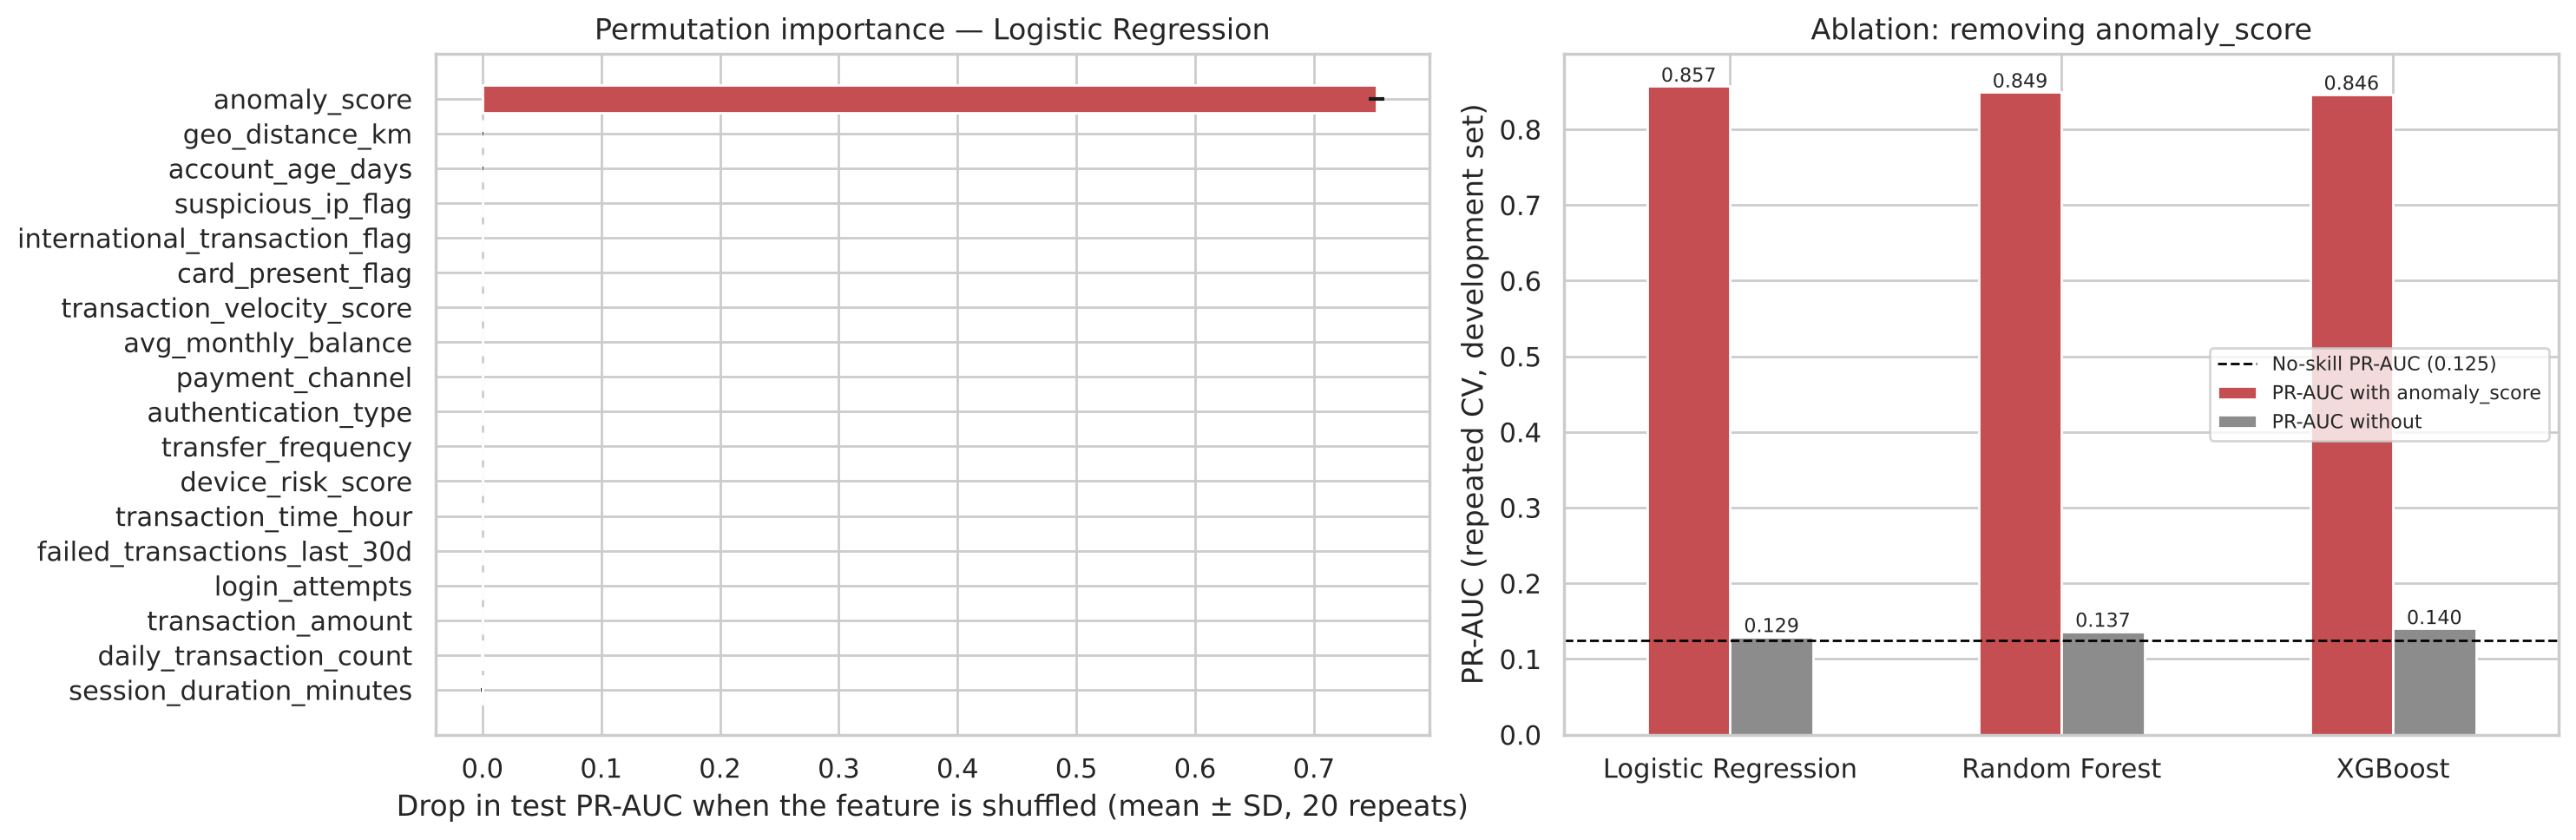

,PR-AUC with anomaly_score,PR-AUC without,sd (without),ROC-AUC without
Logistic Regression,0.8570,0.1295,0.0069,0.4983
Random Forest,0.8493,0.1365,0.0093,0.4982
XGBoost,0.8463,0.1401,0.0101,0.4997


Permutation importance of anomaly_score: 0.753; largest among all other features: 0.0004


In [28]:
pi = permutation_importance(final_model, X_test, y_test, scoring="average_precision", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
pi_s = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=X_test.columns).sort_values("mean")

abl_pipes = {n: make_pipeline(clone(tuned[n].named_steps["model"]), drop=("anomaly_score",)) for n in tuned}
abl_folds, abl_summary = cv_table(abl_pipes, X_dev, y_dev, cv=rcv)
abl = pd.DataFrame({"PR-AUC with anomaly_score": cmp_summary.loc[list(tuned), "pr_auc"], "PR-AUC without": abl_summary["pr_auc"],
                    "sd (without)": abl_summary["pr_auc_sd"], "ROC-AUC without": abl_summary["roc_auc"]})

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(pi_s.index, pi_s["mean"], xerr=pi_s["sd"], color=[C_FRAUD if v > 0.01 else C_NEUTRAL for v in pi_s["mean"]])
axes[0].set_xlabel("Drop in test PR-AUC when the feature is shuffled (mean ± SD, 20 repeats)")
axes[0].set_title(f"Permutation importance — {FINAL_NAME}")
abl[["PR-AUC with anomaly_score", "PR-AUC without"]].plot.bar(ax=axes[1], color=[C_FRAUD, C_NEUTRAL], rot=0)
axes[1].axhline(y_dev.mean(), color="black", ls="--", lw=1, label=f"No-skill PR-AUC ({y_dev.mean():.3f})")
axes[1].set_ylabel("PR-AUC (repeated CV, development set)"); axes[1].set_title("Ablation: removing anomaly_score"); axes[1].legend(fontsize=8)
for c in axes[1].containers: axes[1].bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.show()
display(abl)
print(f"Permutation importance of anomaly_score: {pi_s.loc['anomaly_score', 'mean']:.3f}; largest among all other features: {pi_s.drop('anomaly_score')['mean'].max():.4f}")

**Findings**

- **Permutation importance.** Shuffling `anomaly_score` lowers test PR-AUC by about 0.75 — from 0.88 to roughly the no-skill level. Shuffling any other feature changes it by less than 0.001.
- **Ablation.** Without `anomaly_score`, all three tuned models fall to PR-AUC ≈ 0.13–0.14 and ROC-AUC ≈ 0.50, which is no better than guessing. Even gradient boosting, which can find non-linear and interaction effects, extracts nothing from the remaining 17 features.

**What this means**

1. The 17 behavioural and contextual features (amount, device risk, velocity, geography, channel, authentication…) carry **no detectable information** about `fraud_flag` in this dataset. In real banking data these are among the strongest fraud predictors; their irrelevance here, together with the near-uniform marginal distributions and zero correlations found in Part 1, strongly suggests that the dataset is **synthetically generated**, with the label derived from `anomaly_score` plus noise.
2. The modelling problem therefore reduces to thresholding one variable, and the performance ceiling is set by how the generator added noise, not by our modelling choices.
3. The leakage question from Section 1.3 becomes decisive: if `anomaly_score` is not available at decision time, **no usable model can be built from this table**.

## 4.7 Post-hoc check: augmentation and model family on the test set

For completeness — and **after** all decisions were frozen — we score on the test set the alternatives that were *not* selected. This is a confirmation of the cross-validated conclusions, not a selection step.

In [29]:
rows = {}
def add_row(label, pipe):
    pipe = clone(pipe)
    o = cross_val_predict(pipe, X_dev, y_dev, cv=cv5, method="predict_proba", n_jobs=-1)[:, 1]
    pr_, rc_, th_ = precision_recall_curve(y_dev, o)
    t_ = th_[np.argmax(5 * pr_[:-1] * rc_[:-1] / np.clip(4 * pr_[:-1] + rc_[:-1], 1e-12, None))]
    pb = pipe.fit(X_dev, y_dev).predict_proba(X_test)[:, 1]
    rows[label] = {"own max-F2 threshold": t_, "PR-AUC": average_precision_score(y_test, pb), "ROC-AUC": roc_auc_score(y_test, pb),
                   **{k: v for k, v in metrics_at(y_test, pb, t_).items() if k != "flagged_%"}, "Brier": brier_score_loss(y_test, pb)}

final_est = tuned[FINAL_NAME].named_steps["model"]
add_row(f"{FINAL_NAME} (final)", tuned[FINAL_NAME])
add_row(f"{FINAL_NAME} + SMOTENC", make_pipeline(clone(final_est), sampler="smotenc"))
add_row(f"{FINAL_NAME} + random oversampling", make_pipeline(clone(final_est), sampler="ros"))
for n in tuned:
    if n != FINAL_NAME: add_row(f"{n} (tuned)", tuned[n])
posthoc = pd.DataFrame(rows).T
display(posthoc)

,own max-F2 threshold,PR-AUC,ROC-AUC,precision,recall,f1,f2,Brier
Logistic Regression (final),0.6648,0.8816,0.9802,0.7179,0.8960,0.7972,0.8537,0.0579
Logistic Regression + SMOTENC,0.4980,0.8733,0.9791,0.6528,0.9400,0.7705,0.8640,0.0520
Logistic Regression + random oversampling,0.5681,0.8790,0.9796,0.6562,0.9240,0.7674,0.8543,0.0580
Random Forest (tuned),0.6533,0.8627,0.9781,0.7296,0.8960,0.8043,0.8569,0.0559
XGBoost (tuned),0.1773,0.8698,0.9783,0.6785,0.9200,0.7810,0.8588,0.0351


**Reading the post-hoc table** (each model at its own F2-optimal threshold, chosen on development data)

- **Augmentation.** On the test set, SMOTENC lowers PR-AUC (0.873 vs 0.882) and random oversampling leaves it unchanged (0.879), matching the cross-validated conclusion. SMOTENC shows a slightly higher F2 (0.864 vs 0.854), but it does so at a different operating point (recall 0.94, precision 0.65) and the difference is far inside the bootstrap interval for F2 (0.82–0.89). It is not evidence of better generalisation.
- **Model family.** Random forest (0.863) and XGBoost (0.870) score below logistic regression (0.882) on PR-AUC, again as predicted by CV. On F2 all five candidates lie between 0.854 and 0.864 — statistically indistinguishable.
- **Calibration.** XGBoost, the only model trained without class weights, has by far the best Brier score (0.035 vs ≈ 0.056–0.058). This confirms the ranking-vs-calibration trade-off noted in Section 3.4.

All cross-validated decisions are confirmed on unseen data; none would have been reversed.

---
# Part 5 — Analytical Reflection

### 5.1 Does the final model generalise?

Within the population this dataset represents, yes. The L1-regularised logistic regression shows no train–validation gap, a flat learning curve, a threshold whose out-of-fold precision and recall (0.71 / 0.90) were reproduced on the untouched test set (0.72 / 0.90), and stable results over 15 CV folds and eight alternative splits (test PR-AUC 0.83–0.89). Our single reported test PR-AUC of 0.88 is on the fortunate side of that range; **≈ 0.86 is the figure we would defend**. The claim is deliberately narrow: this is generalisation to *more rows from the same generator*. Generalisation over time, to new customers, or to another institution was not and could not be tested, because the data contain no timestamp and no customer identifier.

### 5.2 Structural weaknesses

- **The model is one feature.** `anomaly_score` accounts for all of the predictive power: removing it sends every model to chance level (ROC-AUC 0.50), and our tuned model improves on simply ranking by the raw score by 0.002–0.004 PR-AUC. We have built a well-validated threshold on someone else's model, not an independent fraud detector.
- **The provenance of that feature is unknown.** If the score is produced after investigation, or was trained on the same labels, our results are leakage and would vanish in production. This is the largest threat to validity in the project and cannot be resolved from the data alone.
- **The data appear synthetic.** Uniform marginals, zero inter-feature correlation and no signal in variables that drive real fraud (amount, device, geography, velocity) indicate a generator in which the label depends on `anomaly_score` plus noise. Conclusions about *which features matter* should not be transferred to real banking data.
- **An irreducible error floor.** Errors are confined to scores of 0.5–0.8, where no available feature separates the classes. Neither more rows nor more model capacity changes this.
- **Uncalibrated scores.** Balanced class weights inflate predicted probabilities (Brier 0.058 vs 0.035 for an unweighted model).

### 5.3 Real-world deployment risks

- **Upstream dependency and drift.** Any re-training, re-scaling or outage of the anomaly engine changes our model's behaviour immediately; adding noise with SD 0.10 to the score already reduces PR-AUC from 0.88 to 0.81. A missing score would be median-imputed and silently treated as low risk.
- **Adversarial adaptation.** Fraudsters adapt; a rule equivalent to "score > 0.6" is easy to probe and evade, and real fraud is non-stationary in a way a static sample cannot show.
- **Prevalence shift.** Real fraud rates are typically well below 1%, not 12.5%. At equal recall and false-positive rate (5%), precision at a 0.5% base rate would be under 10%, and the alert volume (16% of transactions here) would be operationally unmanageable.
- **Feedback loops and fairness.** Once deployed, only flagged transactions are investigated, so future labels become biased towards what the model already detects. We found no significant performance differences across channels or authentication types, but segment samples are small (14–134 frauds), and no customer attributes are available for a proper fairness audit.
- **Cost assumptions.** The operating point is optimal only if a missed fraud costs about 3–5 times a false alarm; that number must come from the business.

### 5.4 Was augmentation beneficial?

No. Across two learners and four rebalancing strategies, none improved PR-AUC, and SMOTENC reduced it in every fold (−0.007 for logistic regression, −0.051 for random forest). The apparent recall gain at the 0.5 threshold was shown to be a threshold shift: at matched recall, precision was unchanged, while calibration deteriorated. The test set confirmed this. The reason is structural: augmentation addresses *sparsity* of the minority class, whereas our problem is *class overlap*. Synthetic points placed in an overlap region add no information, and in a space with one informative and seventeen noise dimensions, interpolation manufactures spurious structure that flexible models then overfit. Threshold selection achieved the same recall without altering the training distribution. The broader lesson is that imbalance alone does not justify augmentation; it must be shown to be the binding constraint.

### 5.5 Technically grounded future improvements

1. **Establish the lineage of `anomaly_score`** (when it is computed, on what inputs, whether labels were involved). Every other improvement depends on this.
2. **Acquire information that discriminates inside the overlap zone**: customer-level history (deviation from the customer's own spending profile), device and merchant graphs, sequence features. This requires entity IDs and timestamps, and is the only route past the current ceiling.
3. **Validate temporally and by entity** once those fields exist: forward-chaining splits and `GroupKFold` by customer, to measure the drift and dependence we could only assume away.
4. **Recalibrate** the score (Platt or isotonic on out-of-fold predictions, or an analytic prior-shift correction) and re-evaluate with expected calibration error, so that outputs can feed expected-loss calculations.
5. **Move to cost-sensitive decisions**: an expected-cost threshold that depends on transaction amount, and a three-way policy (approve / step-up authentication / block) that sends the ambiguous 0.5–0.8 band to a cheap secondary check instead of forcing a binary decision.
6. **Monitoring in production**: population-stability index on `anomaly_score`, alert-rate and precision tracking, and a small random sample of un-flagged transactions sent for review to obtain unbiased labels and break the feedback loop.
7. **If generative augmentation is revisited** on richer data, restrict it to the decision boundary (Borderline-SMOTE) or use a conditional tabular generator, and always judge it on threshold-free metrics on untouched data, as done here.